# Dental Caries Segmentation: A Practical Data Science Workflow
## Raw inputs → data preparation and EDA → explicit training → evaluation → inference interface

This notebook is a working laboratory for **caries_crop_seg_20261028.pt**. It includes visible Python for dataset construction, parameter configuration, model training, metric calculation, and a local interactive inference interface.

**Learned output:** a one-class YOLOv8s segmentation model predicts caries masks from tooth-image crops. FDI numbering comes from a separate tooth model. Mesial/occlusal/distal labels are derived afterward by geometry.

**PCA placement:** PCA aligns tooth geometry after lesion inference for the surface rule. It does not rotate training images or provide an image feature to the historical detector.

Recorded scores are project validation estimates, not an independent clinical test. Each result below is marked as recorded evidence or a newly requested calculation.

## 00. Execution guide
1. Run setup and raw-data EDA.
2. Inspect the image/annotation contract and every preprocessing parameter.
3. Optionally enable BUILD_DATASET to generate a new dataset and manifest.
4. Inspect TRAIN_CONFIG and enable RUN_TRAINING to call model.train() directly.
5. Select a checkpoint and run crop-level and full-panorama evaluation separately.
6. Inspect PCA, surface agreement, false positives, and false negatives.
7. Use the final upload/select interface to display predictions and JSON.

All expensive flags default to False. Run All reads existing artifacts, computes EDA, displays saved results, defines the complete workflow, and creates interface controls. It does not start training automatically.

This is one notebook within the repository. It requires the project data and weights. Shared XML, segmentation, and geometry utilities are imported explicitly for consistency with serving; the main dataset, training, evaluation, and interface logic is visible here.

In [1]:
from pathlib import Path
from collections import Counter,defaultdict
from dataclasses import asdict
from datetime import datetime,timezone
from contextlib import contextmanager
import copy,hashlib,importlib.metadata,importlib.util,inspect,json,math
import os,platform,random,sys,tempfile,time
import cv2
import numpy as np
import pandas as pd
import yaml
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PolygonPatch
from IPython.display import display,Markdown
pd.set_option("display.max_colwidth",100)
pd.set_option("display.max_rows",160)
plt.rcParams.update({"figure.dpi":105,"axes.grid":False})
SERVICE=None
for root in [Path.cwd().resolve(),*Path.cwd().resolve().parents]:
    for candidate in (root,root/"dental-caries-detection"/"ml-service"):
        if (candidate/"models"/"versions.py").is_file() and (candidate/"app"/"pipeline").is_dir():
            SERVICE=candidate;break
    if SERVICE is not None:break
if SERVICE is None:raise FileNotFoundError("Open the notebook inside the project repository.")
SP_ROOT=SERVICE.parent.parent
if str(SERVICE) not in sys.path:sys.path.insert(0,str(SERVICE))
IMAGE_ROOT=SP_ROOT/"data"/"500 cases with annotation"
WEIGHTS_DIR=SERVICE/"weights"
REFERENCE_DATASET=SERVICE/"datasets"/"caries_crop_v1"
HISTORICAL_RUN=SERVICE/"runs"/"caries_crop_seg"/"v1"
RECORDED_RESULTS=SERVICE.parent/"outputs"
EXPERIMENT_NAME="notebook_practical_20261029"
EXPERIMENT_ROOT=SERVICE/"runs"/EXPERIMENT_NAME
NEW_DATASET=SERVICE/"datasets"/f"{EXPERIMENT_NAME}_crops"
FLAGS=dict(BUILD_DATASET=False,RUN_TOOTH_PREVIEW=False,RUN_TRAINING=False,
           RUN_CROP_EVALUATION=False,RUN_FULL_EVALUATION=False,
           RUN_ONE_IMAGE=False,SHOW_INTERFACE=True)
display(pd.DataFrame([{"item":k,"path":str(v),"exists":v.exists()} for k,v in {
    "service":SERVICE,"raw inputs":IMAGE_ROOT,"weights":WEIGHTS_DIR,
    "reference crops":REFERENCE_DATASET,"training run":HISTORICAL_RUN}.items()]))
display(pd.Series(FLAGS,name="enabled").to_frame())

,item,path,exists
0,service,D:\Mahidol University\SP\dental-caries-detection\ml-service,True
1,raw inputs,D:\Mahidol University\SP\data\500 cases with annotation,True
2,weights,D:\Mahidol University\SP\dental-caries-detection\ml-service\weights,True
3,reference crops,D:\Mahidol University\SP\dental-caries-detection\ml-service\datasets\caries_crop_v1,True
4,training run,D:\Mahidol University\SP\dental-caries-detection\ml-service\runs\caries_crop_seg\v1,True


,enabled
BUILD_DATASET,False
RUN_TOOTH_PREVIEW,False
RUN_TRAINING,False
RUN_CROP_EVALUATION,False
RUN_FULL_EVALUATION,False
RUN_ONE_IMAGE,False
SHOW_INTERFACE,True


### Environment and reproducibility
Default Run All requires NumPy, pandas, Pillow, OpenCV, matplotlib, PyYAML, scikit-learn, ipywidgets, PyTorch, and Ultralytics. PyTorch and Ultralytics are also needed to inspect the trusted checkpoint, even when training is off. Dataset generation, full evaluation, and live inference additionally require a working Detectron2 compiled extension.

Select the **Python (sp_project)** kernel. The environment table below records the actual executable and package versions; a kernel display name alone does not establish its environment. The locally installed environment and the recorded service run can differ.

The original checkpoint records **Ultralytics 8.4.175**. The service audit used **8.4.191 / PyTorch 2.4.1+cu121**. Pin the original version for reproduction, or explicitly record a version change as a new experiment. The training version guard is enabled by default; it does not replace pinning the remaining dependencies, hardware, and source.

Use requirements.txt, requirements-detectron2.txt, and Dockerfile to configure the project ML environment. Detectron2 must match PyTorch/CUDA. Package installation should happen before starting the notebook session.


In [2]:
def package_version(name):
    try:return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:return "not installed"
ENVIRONMENT={"python":platform.python_version(),"python_executable":sys.executable,
             "environment_prefix":sys.prefix,"platform":platform.platform(),**{name:package_version(name) for name in (
    "torch","torchvision","ultralytics","numpy","opencv-python","opencv-python-headless",
    "pandas","Pillow","PyYAML","ipywidgets","scikit-learn","ipykernel","detectron2")}}
display(pd.Series(ENVIRONMENT,name="installed version").to_frame())
import torch
TRAIN_DEVICE=0 if torch.cuda.is_available() else "cpu"
PIPELINE_DEVICE="cuda" if torch.cuda.is_available() else "cpu"
EXPECTED_TRAIN_VERSION="8.4.175"
ALLOW_VERSION_DRIFT=False
print("CUDA available:",torch.cuda.is_available(),"| device:",PIPELINE_DEVICE)
if torch.cuda.is_available():print("GPU:",torch.cuda.get_device_name(0))
def require_ml_environment(require_crop=False,for_training=False):
    if importlib.util.find_spec("ultralytics") is None:raise ImportError("Ultralytics is required.")
    if require_crop and importlib.util.find_spec("detectron2") is None:
        raise ImportError("Use the project ML environment: this operation needs Detectron2.")
    if require_crop:
        try:
            from detectron2 import _C
        except (ImportError,OSError) as exc:
            raise ImportError("Detectron2 compiled operators must match this PyTorch/CUDA environment.") from exc
    actual=package_version("ultralytics")
    if for_training and actual!=EXPECTED_TRAIN_VERSION and not ALLOW_VERSION_DRIFT:
        raise RuntimeError(f"Expected Ultralytics {EXPECTED_TRAIN_VERSION}, found {actual}. "
                           "Use the original version or explicitly allow a new versioned experiment.")

,installed version
python,3.10.19
python_executable,D:\Users\jaopi\anaconda3\envs\sp_project\python.exe
environment_prefix,D:\Users\jaopi\anaconda3\envs\sp_project
platform,Windows-10-10.0.26300-SP0
torch,2.5.1
torchvision,0.20.1
ultralytics,8.4.6
numpy,2.0.1
opencv-python,4.13.0.90
opencv-python-headless,5.0.0.93


CUDA available: True | device: cuda
GPU: NVIDIA GeForce RTX 4080 Laptop GPU


## 01. Input, label, and output contract

| Stage | Input | Supervision or output |
|---|---|---|
| Raw cases | case N/case_N.png and paired AIM XML files | Panorama pixels and lesion annotations |
| Tooth detection | Panorama and pinned Pano-Seg weights | Predicted FDI, boxes, tooth polygons |
| Crop refinement | Padded tooth-image crop and Detectron2 weights | Refined tooth mask |
| Caries training | Neighbour-suppressed tooth-image crop | Class 0 plus normalized lesion polygon |
| Caries prediction | The same type of tooth crop | Lesion polygon, box, confidence |
| PCA and surface | Predicted tooth polygon, lesion centroid, FDI | Mesial, occlusal, or distal |
| Evaluation | Predictions and held-out XML | IoU matches and metrics |

XML contains a permanent-tooth name, surface name, and closed lesion ROI in **original panorama pixels**. The parser maps tooth names to FDI and ignores unrelated markup.

FDI digit 1 identifies quadrant: Q1 upper right, Q2 upper left, Q3 lower left, Q4 lower right, using the patient's sides. Digit 2 identifies tooth position. Inference reads FDI from the tooth model's class names.

**No XML or ROI is read during image-only inference.** Surface annotation is not a training class for this checkpoint. Multiple lesions remain separate instances even when a presentation layer deduplicates findings by surface.

In [3]:
from models.versions import MODEL_VERSIONS
from app.pipeline.xml_annotations import parse_case_dir
from app.pipeline.coordinate_transform import polygon_centroid
from app.pipeline.detection import run_pano_detection,dedupe_detections,refine_with_crop_segmenter,run_stage1
from app.pipeline.crop_utils import suppress_other_teeth,clip_polygon_to_crop,normalize_polygon
from app.pipeline.surface_heuristic import classify_lesion_surface,findings_for_lesions
from app.pipeline.pca_alignment import perform_pca
from app.pipeline.postprocess import encode_caries_lesions
def sha256_file(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for block in iter(lambda:f.read(1<<20),b""):h.update(block)
    return h.hexdigest()
artifact_table=[]
for role,spec in MODEL_VERSIONS.items():
    path=WEIGHTS_DIR/spec["filename"];actual=sha256_file(path) if path.is_file() else None
    artifact_table.append(dict(role=role,artifact=spec["filename"],architecture=spec["architecture"],
                               classes=spec["num_classes"],exists=path.is_file(),
                               expected_sha256=spec["sha256"],actual_sha256=actual,
                               hash_verified=actual==spec["sha256"]))
display(pd.DataFrame(artifact_table))
PINNED_CARIES=WEIGHTS_DIR/MODEL_VERSIONS["caries_detector"]["filename"]
SOURCE_HASHES={str(path.relative_to(SERVICE)):sha256_file(path) for path in [
    SERVICE/"app/pipeline/detection.py",SERVICE/"app/pipeline/crop_utils.py",
    SERVICE/"app/pipeline/xml_annotations.py",SERVICE/"app/pipeline/pca_alignment.py",
    SERVICE/"app/pipeline/surface_heuristic.py",SERVICE/"app/pipeline/coordinate_transform.py",
    SERVICE/"app/pipeline/postprocess.py",SERVICE/"models/registry.py",SERVICE/"models/versions.py"]}
display(pd.Series(SOURCE_HASHES,name="SHA-256").to_frame())

,role,artifact,architecture,classes,exists,expected_sha256,actual_sha256,hash_verified
0,pano_detector,Tooth_seg_pano_20250319.pt,yolo_segment,32,True,502bd58099e50d5c5bb16245aa5a135943fbd87debe9f66928a5b938798ca579,502bd58099e50d5c5bb16245aa5a135943fbd87debe9f66928a5b938798ca579,True
1,crop_segmenter,Tooth_seg_crop_20250424.pth,mask_rcnn_R_50_FPN_3x,1,True,b39fef8288634e6e756d3aace628d145d0f927a76d3f7d9bfa17f919a8c9b4a9,b39fef8288634e6e756d3aace628d145d0f927a76d3f7d9bfa17f919a8c9b4a9,True
2,caries_detector,caries_crop_seg_20261028.pt,yolo_segment,1,True,c0d4768fdbd90567feb28c5df34fa760321e79a08acbb47e11ba84a5c2c67d74,c0d4768fdbd90567feb28c5df34fa760321e79a08acbb47e11ba84a5c2c67d74,True


,SHA-256
app\pipeline\detection.py,17e76d235bd6bf3f03bfd9231447d2cf74ddb542a1b6e702b04c3e9184e9b5eb
app\pipeline\crop_utils.py,ee719151ec477c4cf9f49b34cdd0a23cf8f0ac1215e3234ba057643cbdb516ac
app\pipeline\xml_annotations.py,f507f49b30d37c535a7e49ed8926b5091570879af17f766f066e8ae671e6669d
app\pipeline\pca_alignment.py,4a92389d8d44c46dd10b619b16a9b87a901fdf632ce2e2a19a392d6e10330b81
app\pipeline\surface_heuristic.py,80caa3a0db46bc2050d6918f00ecc3d2f919638e60ddc269a63449aff2f5907c
app\pipeline\coordinate_transform.py,64dc61b893c9098381b7729fab24276a9216e2bf6c25f8fb9040d02a87653ab0
app\pipeline\postprocess.py,7dfaa3c58300e14d443b547ea75565e2c92cb569e8d0967772be5ce1abec4e28
models\registry.py,2a3f14139522bed5c211c88c65b40daee9c094c25ea76bdccb73afd1cd72ab4a
models\versions.py,744ecb33f9461751f2b0df31703a130b12df59dcc67fd35cef6e79f9ee459f5a


## 02. Raw-data EDA
**Question:** Are images paired with usable annotations, and what lesion groups are represented?
Inventory image dimensions, XML counts, surface labels, FDI quadrants, and polygon areas. Area is a geometric proxy, not clinical severity. A case without parsed lesions could be negative, incomplete, unsupported, or a parsing failure; review issues before calling it normal.

In [4]:
case_dirs=sorted([d for d in IMAGE_ROOT.glob("case *") if d.is_dir() and d.name.split()[-1].isdigit()],
                 key=lambda d:int(d.name.split()[-1]))
case_records=[];lesion_records=[];annotation_issues=[];XML_BY_CASE={}
for case_dir in case_dirs:
    cid=int(case_dir.name.split()[-1]);image_path=case_dir/f"case_{cid}.png"
    lesions,issues=parse_case_dir(case_dir);XML_BY_CASE[cid]=lesions
    width=height=None
    if image_path.is_file():
        with Image.open(image_path) as image:width,height=image.size
    case_records.append(dict(case_id=cid,image_path=str(image_path),image_exists=image_path.is_file(),
                             width=width,height=height,xml_files=len(list(case_dir.glob("*.xml"))),
                             lesions=len(lesions),positive_teeth=len({l.fdi for l in lesions}),
                             parser_issues=len(issues)))
    for lesion in lesions:
        poly=np.asarray(lesion.polygon,dtype=np.float32)
        lesion_records.append(dict(case_id=cid,fdi=lesion.fdi,quadrant=lesion.fdi//10,
                                   surface=lesion.surface,vertices=len(poly),
                                   polygon_area_pixels=abs(float(cv2.contourArea(poly))),
                                   source_file=lesion.source_file))
    annotation_issues.extend({"case_id":cid,**asdict(issue)} for issue in issues)
case_df=pd.DataFrame(case_records);lesion_df=pd.DataFrame(lesion_records)
if case_df.empty:raise FileNotFoundError(f"No case folders found: {IMAGE_ROOT}")
print(f"Cases: {len(case_df)} | XML lesions: {len(lesion_df)}")
display(case_df.head())
display(case_df[["width","height","xml_files","lesions","positive_teeth"]].describe())
display(pd.DataFrame(annotation_issues).head(20))

Cases: 500 | XML lesions: 1979


,case_id,image_path,image_exists,width,height,xml_files,lesions,positive_teeth,parser_issues
0,1,D:\Mahidol University\SP\data\500 cases with annotation\case 1\case_1.png,True,3036,1536,4,4,4,0
1,2,D:\Mahidol University\SP\data\500 cases with annotation\case 2\case_2.png,True,3036,1536,5,5,4,0
2,3,D:\Mahidol University\SP\data\500 cases with annotation\case 3\case_3.png,True,3037,1536,9,9,8,0
3,4,D:\Mahidol University\SP\data\500 cases with annotation\case 4\case_4.png,True,3037,1536,11,11,8,0
4,5,D:\Mahidol University\SP\data\500 cases with annotation\case 5\case_5.png,True,3036,1536,8,8,7,0


,width,height,xml_files,lesions,positive_teeth
count,500.000000,500.0,500.000000,500.000000,500.00000
mean,3035.376000,1536.0,3.958000,3.958000,3.62600
std,14.818292,0.0,2.622593,2.622593,2.25217
min,2705.000000,1536.0,1.000000,1.000000,1.00000
25%,3036.000000,1536.0,2.000000,2.000000,2.00000
50%,3036.000000,1536.0,3.000000,3.000000,3.00000
75%,3036.000000,1536.0,5.000000,5.000000,5.00000
max,3037.000000,1536.0,16.000000,16.000000,13.00000


""


Missing images: 0
Cases with zero parsed lesions: 0
Parser issues: 0


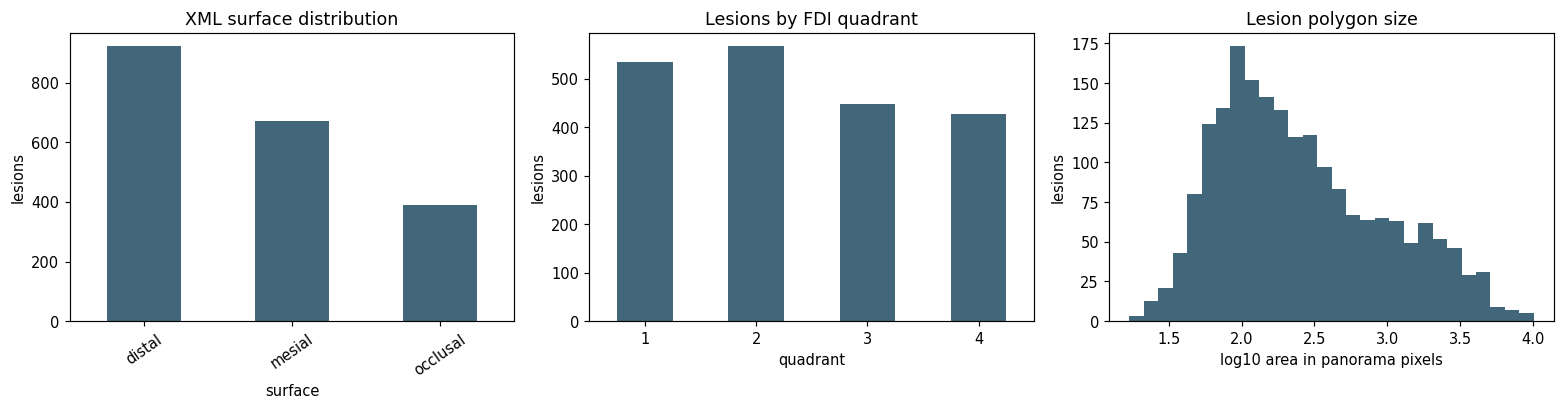

In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
lesion_df["surface"].value_counts().plot.bar(ax=axes[0],color="#42677A",rot=35)
axes[0].set(title="XML surface distribution",ylabel="lesions",xlabel="surface")
lesion_df["quadrant"].value_counts().sort_index().plot.bar(ax=axes[1],color="#42677A",rot=0)
axes[1].set(title="Lesions by FDI quadrant",ylabel="lesions",xlabel="quadrant")
axes[2].hist(np.log10(lesion_df["polygon_area_pixels"].clip(lower=1)),bins=28,color="#42677A")
axes[2].set(title="Lesion polygon size",xlabel="log10 area in panorama pixels",ylabel="lesions")
plt.tight_layout()
print("Missing images:",int((~case_df["image_exists"]).sum()))
print("Cases with zero parsed lesions:",int((case_df["lesions"]==0).sum()))
print("Parser issues:",len(annotation_issues))

,case_id,fdi,quadrant,surface,vertices,polygon_area_pixels
48,10,26,2,distal,44,725.239919
49,10,27,2,mesial,29,165.049495


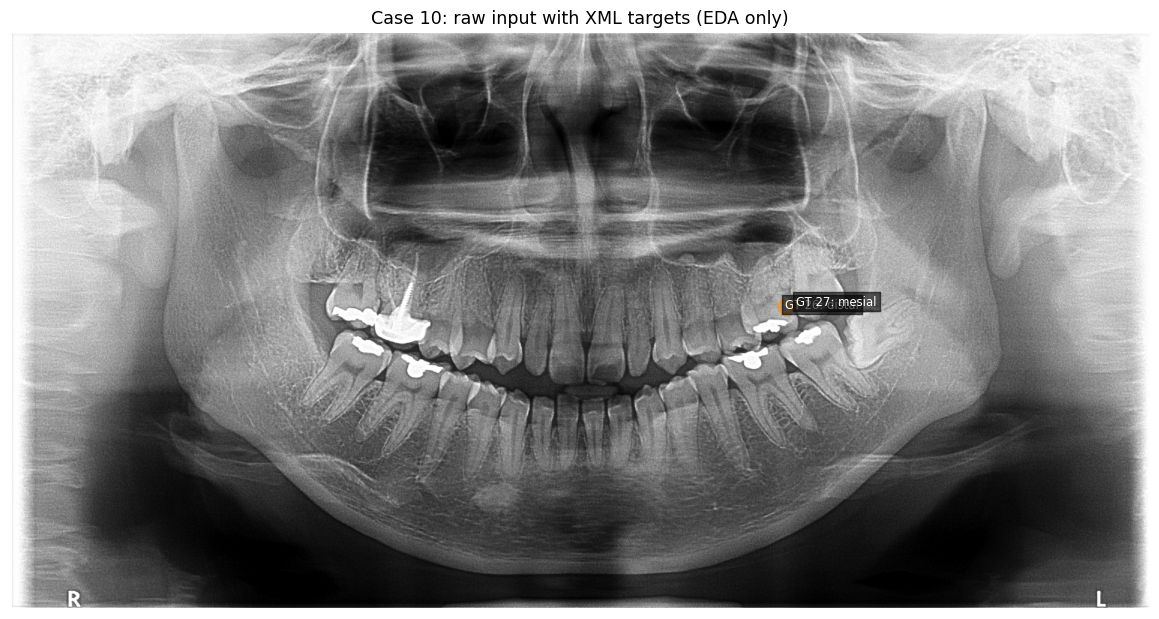

In [6]:
EXAMPLE_CASE=10
example_row=case_df.loc[case_df.case_id==EXAMPLE_CASE].iloc[0]
example_image=cv2.imread(example_row.image_path)
fig,ax=plt.subplots(figsize=(15,6))
ax.imshow(cv2.cvtColor(example_image,cv2.COLOR_BGR2RGB))
for lesion in XML_BY_CASE[EXAMPLE_CASE]:
    ax.add_patch(PolygonPatch(np.asarray(lesion.polygon),closed=True,fill=False,
                              edgecolor="#E79B37",linewidth=2))
    ax.text(*lesion.centroid,f"GT {lesion.fdi}: {lesion.surface}",color="white",
            bbox={"facecolor":"black","alpha":0.6,"pad":2},fontsize=8)
ax.set_title(f"Case {EXAMPLE_CASE}: raw input with XML targets (EDA only)")
ax.axis("off");plt.tight_layout()
display(lesion_df[lesion_df.case_id==EXAMPLE_CASE].drop(columns="source_file"))

## 03. Data preparation: exact steps and parameters
The historical detector sees **unrotated tooth-image crops**. PCA pixel rotation, CLAHE, and ROI-coordinate feature vectors are not part of this training path.

1. Pano-Seg predicts tooth polygons, boxes, and FDI.
2. Deduplicate by FDI and keep the highest-confidence instance.
3. Expand the original box by 20 panorama pixels and clamp to the image.
4. Refine the tooth mask with Detectron2; keep the original crop window.
5. Black out other teeth, preserving a 15-pixel dilation around the target mask.
6. Group XML lesions by FDI; rasterize, clip to crop, and keep the largest visible contour.
7. Normalize targets: `x_norm=x_crop/W`, `y_norm=y_crop/H`.
8. Keep positives and sample up to three unannotated teeth per case as negatives.
9. Skip a known-positive tooth when no target survives clipping.
10. Write images, labels, and a lineage manifest.

A lesion found in a crop inherits its FDI. Padding can contain adjacent lesions; ownership is an assumption to audit, not a guarantee.

**Colour contract:** shared Crop-Seg code reverses channels despite its BGR config. Equal grayscale channels hide the difference in audited radiographs. This notebook preserves the shared implementation for parity; changing it requires controlled comparison and a new dataset.

In [7]:
PREP=dict(seed=42,split_seed=43,val_fraction=0.20,pano_conf=0.25,pano_iou=0.70,
          pano_imgsz=640,dedupe_iou=0.50,crop_pad=20,crop_seg_enabled=True,
          crop_seg_score=0.50,crop_seg_min_size=800,crop_seg_max_size=1333,
          suppress_neighbours=True,preserve_pad=15,negatives_per_case=3,
          min_lesion_area=4.0,label_contour_epsilon=0.002,label_decimal_places=6)
PREP_MEANING={
 "seed":"Random generator for selecting negative teeth.",
 "split_seed":"Independent generator for validation cases; historical seed+1.",
 "val_fraction":"Fraction of whole cases held for validation.",
 "pano_conf":"Minimum confidence of tooth predictions.",
 "pano_iou":"Tooth YOLO NMS IoU, not lesion-match IoU.",
 "pano_imgsz":"YOLO target input size with aspect-preserving letterboxing.",
 "dedupe_iou":"Duplicate overlap threshold; one final instance per FDI.",
 "crop_pad":"Padding in original panorama pixels.",
 "crop_seg_enabled":"Use Detectron2 before suppression.",
 "crop_seg_score":"Pinned Detectron2 ROI-head score threshold.",
 "crop_seg_min_size":"Shortest edge after Detectron2 resize.",
 "crop_seg_max_size":"Maximum edge after Detectron2 resize.",
 "suppress_neighbours":"Remove predicted neighbouring tooth regions.",
 "preserve_pad":"Dilation radius around target mask, in crop pixels.",
 "negatives_per_case":"Maximum unannotated tooth crops sampled per case.",
 "min_lesion_area":"Minimum visible raster/contour area in crop pixels.",
 "label_contour_epsilon":"Simplification factor times perimeter; shared helper constant.",
 "label_decimal_places":"Normalized target serialization precision."}
display(pd.DataFrame([dict(parameter=k,value=str(v),meaning=PREP_MEANING[k]) for k,v in PREP.items()]))
print("Suppression signature:",inspect.signature(suppress_other_teeth))
print("Clipping signature:",inspect.signature(clip_polygon_to_crop))

,parameter,value,meaning
0,seed,42,Random generator for selecting negative teeth.
1,split_seed,43,Independent generator for validation cases; historical seed+1.
2,val_fraction,0.2,Fraction of whole cases held for validation.
3,pano_conf,0.25,Minimum confidence of tooth predictions.
4,pano_iou,0.7,"Tooth YOLO NMS IoU, not lesion-match IoU."
5,pano_imgsz,640,YOLO target input size with aspect-preserving letterboxing.
6,dedupe_iou,0.5,Duplicate overlap threshold; one final instance per FDI.
7,crop_pad,20,Padding in original panorama pixels.
8,crop_seg_enabled,True,Use Detectron2 before suppression.
9,crop_seg_score,0.5,Pinned Detectron2 ROI-head score threshold.


Suppression signature: (crop: 'np.ndarray', crop_bbox: 'BBoxXYXY', target_polygon: 'list[list[float]]', other_polygons: 'list[list[list[float]]]', preserve_pad: 'int' = 15) -> 'np.ndarray'
Clipping signature: (polygon_pano: 'list[list[float]]', crop_bbox: 'BBoxXYXY', min_area: 'float' = 4.0) -> 'list[list[float]] | None'


### Split by case before writing crops
The original builder samples negatives with seed 42 and validation names with seed 43. Every crop from a case stays in one split. This prevents case overlap, not necessarily patient overlap.
There is no independent test split in v1: validation informed checkpoint and threshold choices. Reserve a separate test before model selection in future work.
This case split applies to the caries training dataset. The training-case membership of the pinned Pano-Seg and Crop-Seg checkpoints has not been established here. Complete-system independence also requires upstream-model split provenance and patient identifiers.


In [8]:
manifest=json.loads((REFERENCE_DATASET/"manifest.json").read_text(encoding="utf-8"))
split_rng=random.Random(PREP["split_seed"])
n_val=max(1,round(len(case_dirs)*PREP["val_fraction"]))
val_names=set(split_rng.sample([d.name for d in case_dirs],n_val))
NEW_SPLIT={int(d.name.split()[-1]):("val" if d.name in val_names else "train") for d in case_dirs}
REFERENCE_SPLIT={int(cid):info["split"] for cid,info in manifest["cases"].items()}
print("Historical split:",Counter(REFERENCE_SPLIT.values()))
print("Reconstructed split:",Counter(NEW_SPLIT.values()))
print("Case assignments reproduced:",NEW_SPLIT==REFERENCE_SPLIT)
display(pd.crosstab(pd.Series(REFERENCE_SPLIT,name="split"),
                    pd.Series({cid:("has lesion" if XML_BY_CASE.get(cid) else "no parsed lesion")
                               for cid in REFERENCE_SPLIT},name="annotation status")))

Historical split: Counter({'train': 400, 'val': 100})
Reconstructed split: Counter({'train': 400, 'val': 100})
Case assignments reproduced: True


annotation status,has lesion
split,
train,400
val,100


In [9]:
class ExplicitYOLO:
    # Pass explicit notebook options through the shared serving stage.
    def __init__(self,model,**options):self.model=model;self.options=options
    @property
    def names(self):return self.model.names
    def predict(self,*args,**kwargs):return self.model.predict(*args,**{**self.options,**kwargs})

def load_tooth_models():
    require_ml_environment(require_crop=True)
    from ultralytics import YOLO
    from models.registry import _load_detectron2_crop
    for role in ("pano_detector","crop_segmenter"):
        spec=MODEL_VERSIONS[role]
        assert sha256_file(WEIGHTS_DIR/spec["filename"])==spec["sha256"],role
    pano=ExplicitYOLO(YOLO(str(WEIGHTS_DIR/MODEL_VERSIONS["pano_detector"]["filename"])),
                      device=TRAIN_DEVICE,imgsz=PREP["pano_imgsz"],iou=PREP["pano_iou"],
                      rect=True,retina_masks=False,half=False,max_det=300)
    crop=_load_detectron2_crop(WEIGHTS_DIR,device=PIPELINE_DEVICE)
    cfg=crop["cfg"]
    assert cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST==PREP["crop_seg_score"]
    assert cfg.INPUT.MIN_SIZE_TEST==PREP["crop_seg_min_size"]
    assert cfg.INPUT.MAX_SIZE_TEST==PREP["crop_seg_max_size"]
    return dict(pano=pano,crop=crop)

def detect_refined_teeth(image_path,models):
    image=cv2.imread(str(image_path))
    if image is None:raise ValueError(f"Unreadable image: {image_path}")
    teeth=run_pano_detection(str(image_path),models["pano"],PREP["pano_conf"])
    teeth=dedupe_detections(teeth,PREP["dedupe_iou"])
    teeth=refine_with_crop_segmenter(image,teeth,models["crop"],pad=PREP["crop_pad"])
    return image,teeth

def make_training_crop(image,target,teeth):
    x1,y1,x2,y2=target.crop_bbox_xyxy;crop=image[y1:y2,x1:x2]
    if PREP["suppress_neighbours"]:
        crop=suppress_other_teeth(crop,target.crop_bbox_xyxy,target.tooth_polygon,
                                  [d.tooth_polygon for d in teeth if d is not target],
                                  preserve_pad=PREP["preserve_pad"])
    return crop

### Optional single-case preprocessing preview
Enable RUN_TOOTH_PREVIEW after Detectron2 is available. Inspect the raw padded crop, refined target mask, and suppressed crop with XML targets before generating all crops.

In [10]:
if FLAGS["RUN_TOOTH_PREVIEW"]:
    tooth_models=load_tooth_models()
    preview_image,preview_teeth=detect_refined_teeth(example_row.image_path,tooth_models)
    target=next(d for d in preview_teeth if d.fdi==26)
    x1,y1,x2,y2=target.crop_bbox_xyxy
    raw_crop=preview_image[y1:y2,x1:x2];prepared=make_training_crop(preview_image,target,preview_teeth)
    fig,axes=plt.subplots(1,3,figsize=(12,5))
    for ax,im,title in zip(axes,[raw_crop,raw_crop,prepared],
                          ["Raw padded crop","Predicted tooth mask","Training input and XML labels"]):
        ax.imshow(cv2.cvtColor(im,cv2.COLOR_BGR2RGB));ax.set_title(title);ax.axis("off")
    axes[1].add_patch(PolygonPatch(np.asarray(target.tooth_polygon)-[x1,y1],fill=False,edgecolor="cyan"))
    for lesion in XML_BY_CASE[EXAMPLE_CASE]:
        if lesion.fdi==target.fdi:
            poly=clip_polygon_to_crop(lesion.polygon,target.crop_bbox_xyxy,min_area=PREP["min_lesion_area"])
            if poly:axes[2].add_patch(PolygonPatch(poly,fill=False,edgecolor="orange"))
    plt.tight_layout()
    print("Mask source:",target.mask_source,"| crop:",target.crop_bbox_xyxy)
else:print("Preprocessing preview is off; no tooth model has been loaded.")

Preprocessing preview is off; no tooth model has been loaded.


### Implement dataset generation
The main loop is visible below. It reuses shared segmentation helpers, while exposing sampling, clipping, normalization, labels, and bookkeeping.

A label row is **0 x1 y1 x2 y2 ...**, with normalized coordinates and at least three vertices. An empty label file denotes a sampled negative. Surface names are deliberately absent from the one-class training targets.

The notebook records refinement counts per case to reveal fallback to panorama masks. Rebuilding with the same seed is not guaranteed to be byte-identical across software/device versions.

In [11]:
def build_crop_dataset(output_dir):
    if output_dir.exists() and any(output_dir.iterdir()):
        raise FileExistsError(f"Choose an empty new dataset folder: {output_dir}")
    assert PREP["crop_seg_enabled"] is True, "Baseline requires Crop-Seg."
    assert PREP["label_contour_epsilon"]==0.002, "Change the shared clip helper deliberately."
    models=load_tooth_models()
    for split in ("train","val"):
        (output_dir/"images"/split).mkdir(parents=True,exist_ok=True)
        (output_dir/"labels"/split).mkdir(parents=True,exist_ok=True)
    rng=random.Random(PREP["seed"]);stats=Counter();per_case={};issues=[]
    start=time.perf_counter()
    for n_case,case_dir in enumerate(case_dirs,1):
        cid=int(case_dir.name.split()[-1]);image_path=case_dir/f"case_{cid}.png"
        if not image_path.exists():
            issues.append({"case":cid,"reason":"missing image"});continue
        image,teeth=detect_refined_teeth(image_path,models)
        lesions,xml_issues=parse_case_dir(case_dir)
        issues.extend({"case":cid,**asdict(i)} for i in xml_issues)
        by_fdi=defaultdict(list)
        for lesion in lesions:by_fdi[lesion.fdi].append(lesion)
        negative_pool=[d for d in teeth if not by_fdi[d.fdi]]
        negatives={d.fdi for d in rng.sample(
            negative_pool,min(len(negative_pool),PREP["negatives_per_case"]))}
        split=NEW_SPLIT[cid];written=used=0
        for target in teeth:
            positive=bool(by_fdi[target.fdi])
            if not positive and target.fdi not in negatives:
                stats["crops_skipped_negative_sampling"]+=1;continue
            crop=make_training_crop(image,target,teeth)
            if crop.size==0:
                stats["crops_skipped_empty"]+=1;continue
            lines=[]
            for lesion in by_fdi[target.fdi]:
                poly=clip_polygon_to_crop(lesion.polygon,target.crop_bbox_xyxy,
                                          min_area=PREP["min_lesion_area"])
                if poly is None:
                    stats["lesions_skipped_outside_crop"]+=1;continue
                norm=normalize_polygon(poly,crop.shape[:2])
                if len(norm)<3:
                    stats["lesions_skipped_degenerate"]+=1;continue
                digits=PREP["label_decimal_places"]
                coords=" ".join(f"{x:.{digits}f} {y:.{digits}f}" for x,y in norm)
                lines.append(f"0 {coords}")
            if positive and not lines:
                stats["crops_skipped_positive_without_visible_lesion"]+=1;continue
            stem=f"case{cid:03d}_fdi{target.fdi}"
            if not cv2.imwrite(str(output_dir/"images"/split/f"{stem}.png"),crop):
                raise IOError(f"Could not write {stem}")
            (output_dir/"labels"/split/f"{stem}.txt").write_text(
                "\n".join(lines)+("\n" if lines else ""),encoding="utf-8")
            written+=1;used+=len(lines)
            stats[f"crops_{split}"]+=1
            stats["crops_positive" if lines else "crops_negative"]+=1
            stats["lesions_used"]+=len(lines)
        per_case[str(cid)]=dict(split=split,lesions_xml=len(lesions),crops=written,
                                lesions_used=used,detected_teeth=len(teeth),
                                refined_teeth=sum(d.mask_source=="crop_seg" for d in teeth))
        stats["cases_used"]+=1
        if n_case%25==0:
            print(f"{n_case}/{len(case_dirs)} cases, {time.perf_counter()-start:.1f}s")
    data=dict(path=str(output_dir.resolve()),train="images/train",val="images/val",names=["caries"])
    (output_dir/"data.yaml").write_text(yaml.safe_dump(data),encoding="utf-8")
    report=dict(created_at=datetime.now(timezone.utc).isoformat(),prep=PREP,
                environment=ENVIRONMENT,source_hashes=SOURCE_HASHES,models=artifact_table,
                cases=per_case,stats=dict(stats),issues=issues)
    (output_dir/"manifest.json").write_text(json.dumps(report,indent=2),encoding="utf-8")
    return report

if FLAGS["BUILD_DATASET"]:
    generated_manifest=build_crop_dataset(NEW_DATASET)
    DATASET=NEW_DATASET
    display(pd.Series(generated_manifest["stats"],name="count").to_frame())
else:
    DATASET=REFERENCE_DATASET
    print("Reading existing v1 crops; no dataset was regenerated:",DATASET)

Reading existing v1 crops; no dataset was regenerated: D:\Mahidol University\SP\dental-caries-detection\ml-service\datasets\caries_crop_v1


## 04. Dataset EDA and validation before training
Verify image/label pairing, numeric class ids, finite normalized coordinates, at least three vertices, valid bounds, positive/negative balance, lesion counts, and case overlap. Then render examples from both classes.

These checks establish structural validity, not clinical correctness. A tooth without annotation may still have disease. V1 samples three negatives per case and omits many others; serving checks all detected teeth. This difference should motivate a controlled negative-sampling experiment.

,crops,positive_crops,lesion_instances,negative_crops,positive_fraction
split,,,,,
train,2617,1417,1538,1200,0.541460
val,626,326,354,300,0.520767


Dataset problems: 0 | case overlap: 0


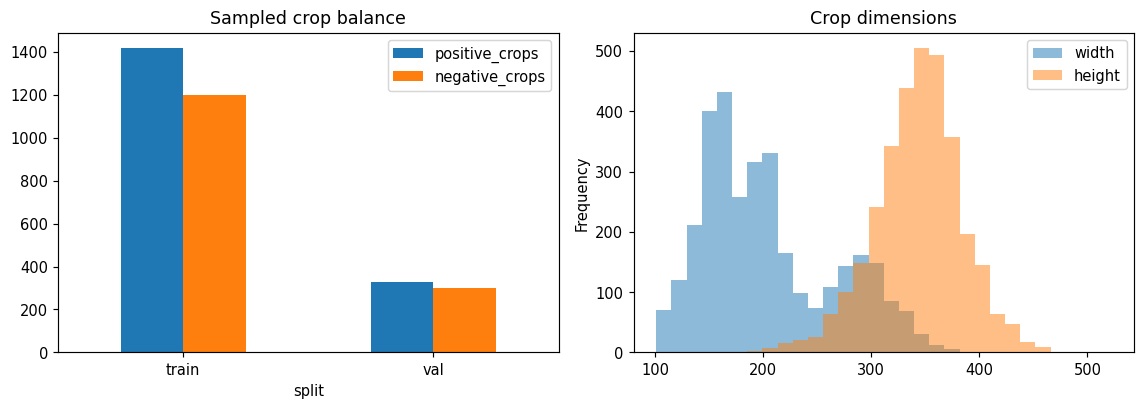

In [12]:
def inspect_dataset(dataset):
    rows=[];problems=[]
    for split in ("train","val"):
        image_dir=dataset/"images"/split;label_dir=dataset/"labels"/split
        images=sorted(image_dir.glob("*.png"))
        image_stems={p.stem for p in images}
        for label in label_dir.glob("*.txt"):
            if label.stem not in image_stems:problems.append((str(label),"orphan label"))
        if not images:problems.append((split,"empty image split"))
        for image_path in images:
            label_path=label_dir/f"{image_path.stem}.txt"
            if not label_path.exists():
                problems.append((image_path.name,"missing label"));continue
            with Image.open(image_path) as im:
                w,h=im.size;im.verify()
            if w<=0 or h<=0:problems.append((image_path.name,"invalid dimensions"))
            lines=[s for s in label_path.read_text(encoding="utf-8").splitlines() if s.strip()]
            for line_no,line in enumerate(lines,1):
                try:values=np.asarray([float(v) for v in line.split()])
                except ValueError:
                    problems.append((label_path.name,f"nonnumeric row {line_no}"));continue
                if len(values)<7 or (len(values)-1)%2 or not np.isfinite(values).all():
                    problems.append((label_path.name,f"invalid row {line_no}"));continue
                if values[0]!=0 or np.any((values[1:]<0)|(values[1:]>1)):
                    problems.append((label_path.name,f"class/bounds error {line_no}"))
                poly=values[1:].reshape(-1,2).astype(np.float32)
                if len(np.unique(poly,axis=0))<3 or cv2.contourArea(poly)<=0:
                    problems.append((label_path.name,f"degenerate polygon {line_no}"))
            cid=int(image_path.stem.split("_")[0].replace("case",""))
            fdi=int(image_path.stem.split("fdi")[-1])
            rows.append(dict(case_id=cid,fdi=fdi,split=split,image=str(image_path),
                             label=str(label_path),positive=bool(lines),lesions=len(lines),
                             width=w,height=h))
    return pd.DataFrame(rows),problems
crop_df,label_problems=inspect_dataset(DATASET)
assert not crop_df.empty,"Dataset has no crops."
summary=crop_df.groupby("split").agg(
    crops=("image","size"),positive_crops=("positive","sum"),lesion_instances=("lesions","sum"))
summary["negative_crops"]=summary.crops-summary.positive_crops
summary["positive_fraction"]=summary.positive_crops/summary.crops
display(summary)
train_ids=set(crop_df.loc[crop_df.split=="train","case_id"])
val_ids=set(crop_df.loc[crop_df.split=="val","case_id"])
assert not(train_ids&val_ids),"Case leakage."
dataset_manifest=json.loads((DATASET/"manifest.json").read_text(encoding="utf-8"))
for row in crop_df.itertuples():
    info=dataset_manifest["cases"].get(str(row.case_id))
    if info is None or info["split"]!=row.split:
        label_problems.append((row.image,"case/manifest split mismatch"))
assert not label_problems,f"Dataset problems: {label_problems[:10]}"
print("Dataset problems:",len(label_problems),"| case overlap:",len(train_ids&val_ids))
fig,axes=plt.subplots(1,2,figsize=(11,4))
summary[["positive_crops","negative_crops"]].plot.bar(ax=axes[0],rot=0,title="Sampled crop balance")
crop_df[["width","height"]].plot.hist(ax=axes[1],bins=30,alpha=0.5,title="Crop dimensions")
plt.tight_layout()


,historical manifest count
crops_train,2617
crops_negative,1500
lesions_used,1892
crops_positive,1743
crops_skipped_negative_sampling,11870
cases_used,500
lesions_skipped_outside_crop,48
crops_val,626
crops_skipped_positive_without_visible_lesion,34


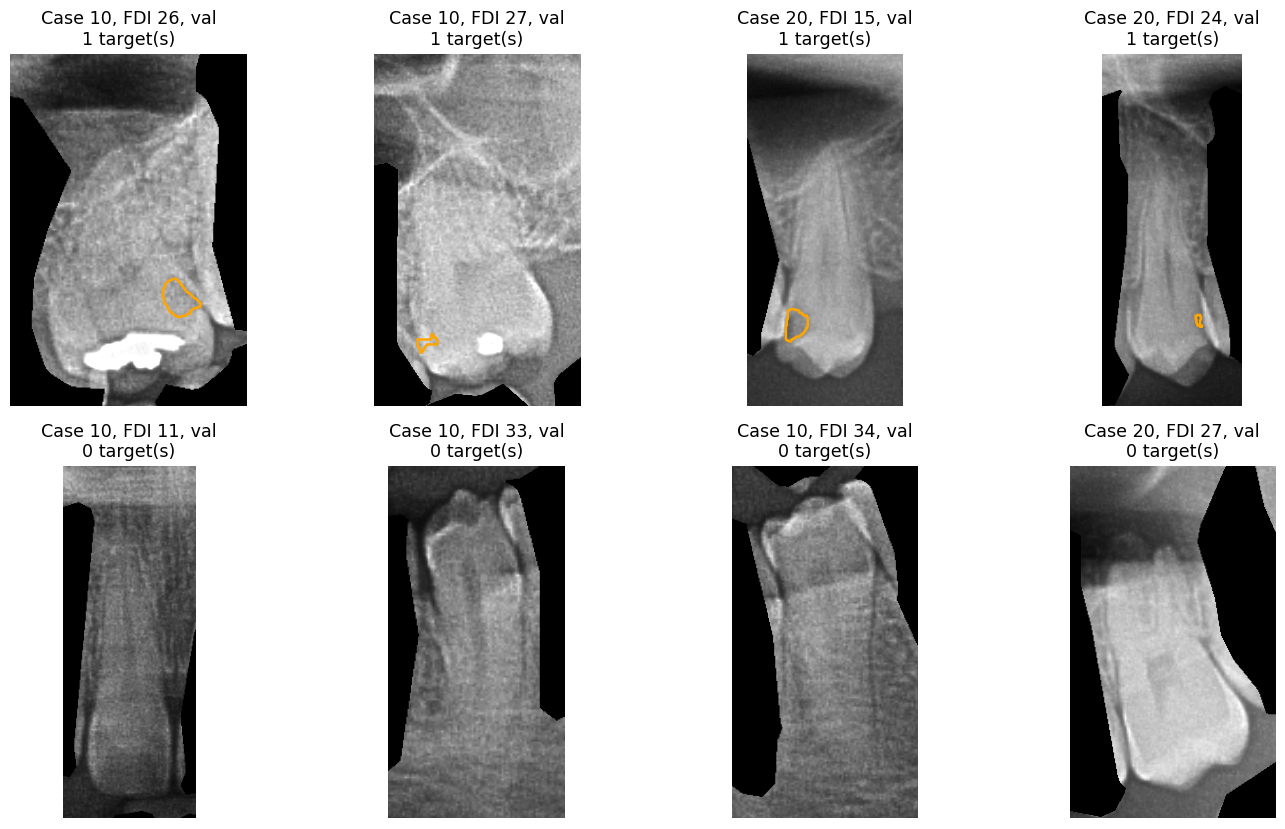

In [13]:
def plot_yolo_crop(row,ax):
    image=cv2.imread(row.image);h,w=image.shape[:2]
    ax.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB))
    for line in Path(row.label).read_text().splitlines():
        if line.strip():
            poly=np.asarray([float(x) for x in line.split()[1:]]).reshape(-1,2)*[w,h]
            ax.add_patch(PolygonPatch(poly,fill=False,edgecolor="orange",linewidth=1.7))
    ax.set_title(f"Case {row.case_id}, FDI {row.fdi}, {row.split}\n{row.lesions} target(s)")
    ax.axis("off")
samples=pd.concat([crop_df[(crop_df.split=="val")&crop_df.positive].head(4),
                   crop_df[(crop_df.split=="val")&~crop_df.positive].head(4)])
fig,axes=plt.subplots(2,4,figsize=(14,8))
for ax,(_,row) in zip(axes.flat,samples.iterrows()):plot_yolo_crop(row,ax)
for ax in axes.flat[len(samples):]:ax.axis("off")
plt.tight_layout()
display(pd.Series(manifest["stats"],name="historical manifest count").to_frame())

### Historical data result
The original dataset contains 500 cases, 400 train/100 validation, 3,243 crops, 1,743 positives, and 1,500 sampled negatives. There are 1,892 targets across splits. Validation has 626 crops and 354 labelled instances; the full-panorama evaluator has 373 XML lesions.

Some annotated teeth/lesions were not retained in saved crops. A crop metric cannot measure upstream misses or lesions lost by cropping. Always report both denominators. V1 has no independent final test set, so use its result as validation/tuning evidence.

## 05. Model training: architecture, learning objective, and every active setting

**Transfer learning:** initialize YOLOv8s-seg from the saved pretrained checkpoint. The trainer adapts its segmentation head to the one-class dataset. It learns radiographic appearance from pixels, not from XML coordinates or PCA features.

**Inputs inside YOLO:** OpenCV images are BGR arrays. Ultralytics handles channel conversion, image augmentation, aspect-preserving resize/letterbox, tensor conversion, and scaling to [0,1]. Do not apply an additional unrecorded normalization. Training uses rect=False; validation/inference can use rectangular letterboxing.

**Objective:** box localization, classification, distribution-focal localization, and instance-mask losses. The relative gains box=7.5, cls=0.5, dfl=1.5 are explicit below. Mask-loss weighting is implementation/version specific; in the inspected v8 segmentation loss it uses the box gain. There is no independent `seg` training argument in this recipe.

**Optimization:** optimizer='auto' is an algorithmic choice, not a fixed optimizer. The original training-container log reports:
- requested auto, nominal lr0=0.01;
- resolved **AdamW, learning rate 0.002, momentum 0.9**;
- best validation-fitness checkpoint at epoch 68;
- early stopping at epoch 88 with patience 20.

In the 8.4.175 source, auto also sets warmup_bias_lr to 0.0, overriding the requested 0.1. Auto selection can ignore nominal lr0 and momentum. The notebook records the actual optimizer object after training. Set a fixed AdamW recipe only as a separately named experiment if you need manual control. Do not call a changed recipe an exact reproduction.
The original package defines segmentation fitness as box mAP50–95 plus mask mAP50–95. The history cell recomputes that criterion and checks its peak against epoch 68. The retained Docker training log is available with docker logs caries-train.


In [14]:
INITIAL_WEIGHTS=SERVICE/"runs"/"pretrained"/"yolov8s-seg.pt"
TRAIN_CONFIG={
    "data":str(EXPERIMENT_ROOT/"dataset.yaml"),
    "epochs":100,"time":None,"patience":20,"imgsz":640,"batch":16,
    "device":TRAIN_DEVICE,"workers":8,
    "optimizer":"auto","lr0":0.01,"lrf":0.01,"momentum":0.937,
    "weight_decay":0.0005,"warmup_epochs":3.0,"warmup_momentum":0.8,
    "warmup_bias_lr":0.1,"cos_lr":False,"nbs":64,
    "box":7.5,"cls":0.5,"dfl":1.5,
    "overlap_mask":True,"mask_ratio":4,"dropout":0.0,
    "seed":42,"deterministic":True,"amp":True,
    "pretrained":True,"freeze":None,"fraction":1.0,
    "cache":False,"rect":False,"multi_scale":0.0,
    "close_mosaic":10,
    "hsv_h":0.015,"hsv_s":0.7,"hsv_v":0.4,
    "degrees":0.0,"translate":0.1,"scale":0.5,"shear":0.0,"perspective":0.0,
    "flipud":0.0,"fliplr":0.5,"bgr":0.0,
    "mosaic":1.0,"mixup":0.0,"cutmix":0.0,"copy_paste":0.0,"copy_paste_mode":"flip",
    "val":True,"split":"val","conf":None,"iou":0.70,"max_det":300,
    "retina_masks":False,
    "save":True,"save_period":-1,"plots":True,"verbose":True,
    "project":str(EXPERIMENT_ROOT/"training"),"name":"baseline",
    "exist_ok":False,"resume":False,
}
# Requested optimizer values above match the historical saved arguments.
# With optimizer='auto', lr0/momentum can be overridden by the trainer.
display(pd.Series(TRAIN_CONFIG,name="explicit requested value").to_frame())
print("Initialization:",INITIAL_WEIGHTS,"| exists:",INITIAL_WEIGHTS.is_file())

,explicit requested value
data,D:\Mahidol University\SP\dental-caries-detection\ml-service\runs\notebook_practical_20261029\dat...
epochs,100
time,None
patience,20
imgsz,640
batch,16
device,0
workers,8
optimizer,auto
lr0,0.01


Initialization: D:\Mahidol University\SP\dental-caries-detection\ml-service\runs\pretrained\yolov8s-seg.pt | exists: True


In [15]:
TRAIN_MEANING={
 "data":"Portable dataset YAML written for this experiment; contains absolute crop-root path.",
 "epochs":"Maximum training epochs, not guaranteed completed epochs.",
 "time":"Optional hour budget; None uses the epoch budget.",
 "patience":"Early-stop window without validation-fitness improvement.",
 "imgsz":"Target size, not a fixed original crop dimension.",
 "batch":"Images per optimization batch; reduce on GPU out-of-memory.",
 "device":"Explicit GPU index or CPU.",
 "workers":"Data-loader processes; use 0 for constrained notebook environments.",
 "optimizer":"auto may choose optimizer and override nominal lr0/momentum.",
 "lr0":"Nominal initial learning rate; ignored when auto chooses another value.",
 "lrf":"Final learning-rate factor relative to initial schedule.",
 "momentum":"Nominal momentum / first-moment setting; auto may override.",
 "weight_decay":"AdamW/optimizer weight regularization on selected parameter groups.",
 "warmup_epochs":"Number of warmup epochs.",
 "warmup_momentum":"Warmup momentum starting value where applicable.",
 "warmup_bias_lr":"Warmup bias-group learning-rate setting.",
 "cos_lr":"False uses the package's non-cosine schedule.",
 "nbs":"Nominal batch size used in trainer accumulation/regularization scaling.",
 "box":"Box-loss gain; inspected segmentation implementation also uses this for mask gain.",
 "cls":"Classification-loss gain.",
 "dfl":"Distribution focal localization-loss gain.",
 "overlap_mask":"Representation of overlapping masks in training targets.",
 "mask_ratio":"Target-mask downsampling ratio.",
 "dropout":"Version/task-dependent dropout setting; not the main regularizer here.",
 "seed":"Random seed, subject to device/library nondeterminism.",
 "deterministic":"Request deterministic operations; not a cross-version identity guarantee.",
 "amp":"Automatic mixed precision where supported.",
 "pretrained":"Use transferred initialization from INITIAL_WEIGHTS.",
 "freeze":"None means no explicitly frozen layer subset.",
 "fraction":"Fraction of training dataset used.",
 "cache":"Whether to cache training images.",
 "rect":"False: standard square training batches rather than rectangular batching.",
 "multi_scale":"Random image-scale training magnitude; zero disables it.",
 "close_mosaic":"Disable mosaic during the final scheduled training epochs.",
 "hsv_h":"Hue augmentation magnitude; colour augmentations may have limited meaning in grayscale.",
 "hsv_s":"Saturation augmentation magnitude.",
 "hsv_v":"Value/brightness augmentation magnitude.",
 "degrees":"Random rotation range in degrees; zero disables.",
 "translate":"Random translation fraction.",
 "scale":"Random spatial scaling magnitude.",
 "shear":"Shear range in degrees.",
 "perspective":"Perspective-warp magnitude.",
 "flipud":"Probability of vertical flip.",
 "fliplr":"Probability of horizontal flip; target is one-class lesion, not surface.",
 "bgr":"Probability of channel-order augmentation; zero disables.",
 "mosaic":"Mosaic probability.",
 "mixup":"MixUp probability.",
 "cutmix":"CutMix probability where supported by the pinned package.",
 "copy_paste":"Segmentation Copy-Paste probability.",
 "copy_paste_mode":"Copy-Paste method; inactive while its probability is zero.",
 "val":"Run validation during training.",
 "split":"Validation split used by the trainer.",
 "conf":"None allows validator default; not production confidence 0.25.",
 "iou":"Validation NMS IoU; not GT matching IoU.",
 "max_det":"Maximum detections per image after postprocessing.",
 "retina_masks":"High-resolution prediction-mask option; false matches baseline.",
 "save":"Save training checkpoints.",
 "save_period":"-1 disables extra periodic checkpoints beyond standard best/last.",
 "plots":"Save standard training/validation plots.",
 "verbose":"Detailed training log.",
 "project":"Parent output directory for this new experiment.",
 "name":"Run directory name.",
 "exist_ok":"False avoids silently reusing an existing run.",
 "resume":"False starts a new fine-tuning run.",
}
assert set(TRAIN_CONFIG)==set(TRAIN_MEANING)
display(pd.DataFrame([dict(parameter=k,value=str(v),meaning=TRAIN_MEANING[k])
                      for k,v in TRAIN_CONFIG.items()]))

,parameter,value,meaning
0,data,D:\Mahidol University\SP\dental-caries-detection\ml-service\runs\notebook_practical_20261029\dat...,Portable dataset YAML written for this experiment; contains absolute crop-root path.
1,epochs,100,"Maximum training epochs, not guaranteed completed epochs."
2,time,None,Optional hour budget; None uses the epoch budget.
3,patience,20,Early-stop window without validation-fitness improvement.
4,imgsz,640,"Target size, not a fixed original crop dimension."
5,batch,16,Images per optimization batch; reduce on GPU out-of-memory.
6,device,0,Explicit GPU index or CPU.
7,workers,8,Data-loader processes; use 0 for constrained notebook environments.
8,optimizer,auto,auto may choose optimizer and override nominal lr0/momentum.
9,lr0,0.01,Nominal initial learning rate; ignored when auto chooses another value.


### Historical full configuration versus active model parameters
The next cell displays **all** original args.yaml entries, including export/display/tracker options saved by Ultralytics. Such metadata entries are not all active in segmentation training. The explicit training dictionary above contains the settings relevant to this recipe.

Flipping a one-class lesion image does not require changing a mesial/distal class because those classes are not trained here. If a future model directly predicts surface classes, its augmentation and FDI conventions must be redesigned together.

Epoch selection uses validation fitness, not mask mAP50 alone. The original log selected epoch 68; the highest mask mAP50 in the CSV occurs at a different epoch. The next cell calculates the latter rather than hard-coding an incorrect epoch.

,original saved argument
task,segment
mode,train
model,/runs/pretrained/yolov8s-seg.pt
data,/out/caries_crop_v1/data.yaml
epochs,100
time,None
patience,20
batch,16
imgsz,640
save,True


Completed epochs: 88
Highest CSV mask mAP50: {'epoch': 74.0, 'metrics/mAP50(M)': 0.50527}
Recomputed historical segmentation-fitness peak: {'epoch': 68.0, 'metrics/mAP50-95(B)': 0.21301, 'metrics/mAP50-95(M)': 0.15948}
Retained caries-train log: AdamW lr=0.002, momentum=0.9; best epoch 68; stopped at 88.
Loss uses a log axis to retain the large first-epoch validation outlier without hiding later epochs.


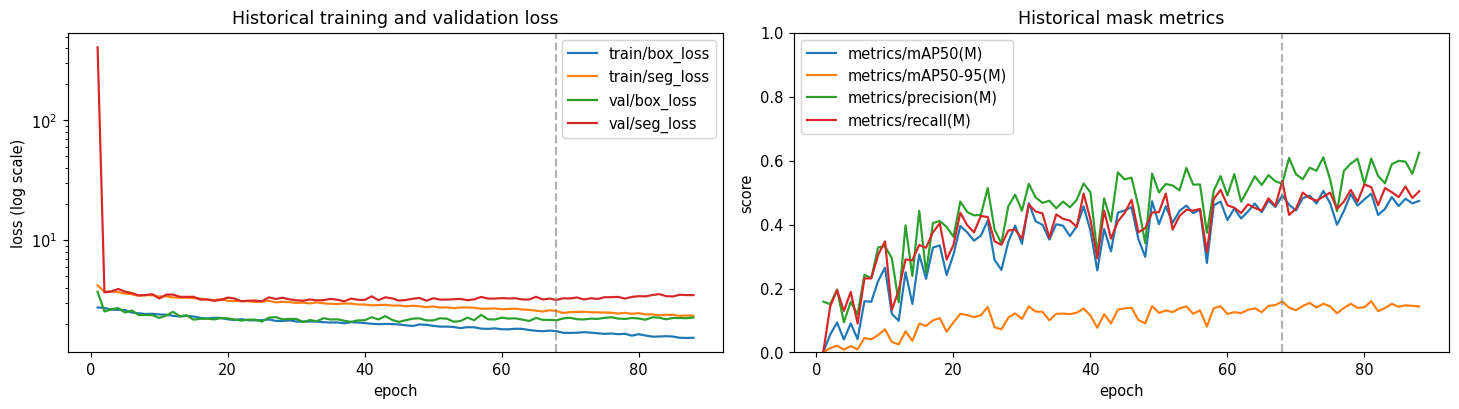

In [16]:
HISTORICAL_ARGS=yaml.safe_load((HISTORICAL_RUN/"args.yaml").read_text(encoding="utf-8"))
display(pd.Series(HISTORICAL_ARGS,name="original saved argument").to_frame())
history=pd.read_csv(HISTORICAL_RUN/"results.csv")
history.columns=history.columns.str.strip()
peak=history.loc[history["metrics/mAP50(M)"].idxmax(),["epoch","metrics/mAP50(M)"]]
print("Completed epochs:",len(history))
print("Highest CSV mask mAP50:",peak.to_dict())
historical_fitness=history["metrics/mAP50-95(B)"]+history["metrics/mAP50-95(M)"]
fitness_peak=history.loc[historical_fitness.idxmax(),["epoch","metrics/mAP50-95(B)","metrics/mAP50-95(M)"]]
print("Recomputed historical segmentation-fitness peak:",fitness_peak.to_dict())
assert int(fitness_peak["epoch"])==68 and len(history)==88
print("Retained caries-train log: AdamW lr=0.002, momentum=0.9; best epoch 68; stopped at 88.")
fig,axes=plt.subplots(1,2,figsize=(14,4))
history.plot(x="epoch",y=["train/box_loss","train/seg_loss","val/box_loss","val/seg_loss"],ax=axes[0])
axes[0].set_yscale("log")
axes[0].set(title="Historical training and validation loss",ylabel="loss (log scale)")
axes[0].axvline(int(fitness_peak["epoch"]),color="gray",linestyle="--",alpha=0.6)
history.plot(x="epoch",y=["metrics/mAP50(M)","metrics/mAP50-95(M)",
                         "metrics/precision(M)","metrics/recall(M)"],ax=axes[1])
axes[1].set(title="Historical mask metrics",ylabel="score",ylim=(0,1))
axes[1].axvline(int(fitness_peak["epoch"]),color="gray",linestyle="--",alpha=0.6)
print("Loss uses a log axis to retain the large first-epoch validation outlier without hiding later epochs.")
plt.tight_layout()

### Execute training directly
The next cell calls **YOLO(...).train(**TRAIN_CONFIG)**, not a hidden shell command.

A portable dataset.yaml is written into the new experiment folder because the historical YAML contains a container path (/out/caries_crop_v1). This avoids an invalid local path without modifying the original dataset.

Training creates a new run, chooses best.pt, copies it to a separate candidate.pt, records the actual optimizer, and writes lineage. It does not overwrite the deployed checkpoint or update the serving manifest.

In [17]:
def local_data_spec(dataset):
    return dict(path=str(dataset.resolve()),train="images/train",val="images/val",names=["caries"])

TRAINED_CHECKPOINT=None
if FLAGS["RUN_TRAINING"]:
    require_ml_environment(for_training=True)
    from ultralytics import YOLO
    import shutil
    if EXPERIMENT_ROOT.exists():
        raise FileExistsError(f"Choose a new EXPERIMENT_NAME: {EXPERIMENT_ROOT}")
    if not INITIAL_WEIGHTS.is_file():raise FileNotFoundError(INITIAL_WEIGHTS)
    EXPERIMENT_ROOT.mkdir(parents=True)
    Path(TRAIN_CONFIG["data"]).write_text(yaml.safe_dump(local_data_spec(DATASET)),encoding="utf-8")
    training_model=YOLO(str(INITIAL_WEIGHTS))
    train_metrics=training_model.train(**TRAIN_CONFIG)
    best=Path(training_model.trainer.best)
    if not best.is_file():raise FileNotFoundError(f"No best checkpoint: {best}")
    TRAINED_CHECKPOINT=EXPERIMENT_ROOT/"candidate.pt"
    shutil.copy2(best,TRAINED_CHECKPOINT)
    actual_optimizer=training_model.trainer.optimizer
    train_record=dict(
        created_at=datetime.now(timezone.utc).isoformat(),
        requested_config=TRAIN_CONFIG,effective_args=vars(training_model.trainer.args),
        actual_optimizer=type(actual_optimizer).__name__,
        optimizer_defaults=actual_optimizer.defaults,
        dataset=str(DATASET),dataset_manifest_sha256=sha256_file(DATASET/"manifest.json"),
        source_hashes=SOURCE_HASHES,environment=ENVIRONMENT,
        initialization_sha256=sha256_file(INITIAL_WEIGHTS),
        candidate=str(TRAINED_CHECKPOINT),candidate_sha256=sha256_file(TRAINED_CHECKPOINT),
    )
    (EXPERIMENT_ROOT/"training_record.json").write_text(
        json.dumps(train_record,indent=2,default=str),encoding="utf-8")
    print("Candidate:",TRAINED_CHECKPOINT)
    print("Actual optimizer:",train_record["actual_optimizer"],actual_optimizer.defaults)
else:
    print("Training is off. Historical curves/results are observations from v1; no new model was fitted.")

Training is off. Historical curves/results are observations from v1; no new model was fitted.


### Verify and choose a checkpoint
A hash match identifies the file; it does not prove model quality. Use the newly trained candidate when available, otherwise the pinned v1 checkpoint. All following evaluation and interface cells reference this choice explicitly.

In [18]:
EVAL_CHECKPOINT=TRAINED_CHECKPOINT if TRAINED_CHECKPOINT is not None else PINNED_CARIES
print("Selected checkpoint:",EVAL_CHECKPOINT)
print("SHA-256:",sha256_file(EVAL_CHECKPOINT))
print("Original best.pt matches pinned serving artifact:",
      sha256_file(HISTORICAL_RUN/"weights"/"best.pt")==sha256_file(PINNED_CARIES))
# Trusted local project checkpoint only; do not load an untrusted pickle.
checkpoint=torch.load(EVAL_CHECKPOINT,map_location="cpu",weights_only=False)
display(pd.Series({k:checkpoint.get(k) for k in ("version","date")},name="metadata").to_frame())
display(pd.Series(checkpoint.get("train_metrics",{}),name="embedded training-time metric").to_frame())
del checkpoint

Selected checkpoint: D:\Mahidol University\SP\dental-caries-detection\ml-service\weights\caries_crop_seg_20261028.pt
SHA-256: c0d4768fdbd90567feb28c5df34fa760321e79a08acbb47e11ba84a5c2c67d74
Original best.pt matches pinned serving artifact: True
WARNING Ultralytics settings reset to default values. This may be due to a possible problem with your settings or a recent ultralytics package update. 
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\jaopi\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


,metadata
version,8.4.175
date,2026-10-28T15:35:42.636906+00:00


,embedded training-time metric
metrics/precision(B),0.58437
metrics/recall(B),0.58384
metrics/mAP50(B),0.55996
metrics/mAP50-95(B),0.21301
metrics/precision(M),0.52767
metrics/recall(M),0.53672
metrics/mAP50(M),0.49127
metrics/mAP50-95(M),0.15948
val/box_loss,2.13402
val/seg_loss,3.15711


## 06. Image-only inference and PCA: where each operation belongs

### Learned inference path
Panorama → predicted FDI/tooth mask → fixed padded crop → Crop-Seg refinement → neighbour suppression → caries mask prediction → crop-to-panorama coordinate transform.

YOLO applies confidence filtering and non-maximum suppression (NMS). A lesion polygon and box are translated back by the crop's top-left offset. A missing segmentation polygon currently falls back to a box polygon in the shared implementation; such fallback should be logged when evaluating mask quality.

### Why PCA is used afterward
Tilted teeth change the image's horizontal direction. A fixed panorama-x rule can put a lesion in the wrong surface zone. PCA estimates axes from the **predicted tooth polygon**, then the same rotation is applied to the tooth and lesion centroid.

For tooth points $p_i$, center $c=\frac{1}{N}\sum p_i$; analyze the covariance of $(p_i-c)$. Eigenvectors describe dominant geometric directions. The project chooses the axis closest to vertical, resolves its direction using upper/lower jaw, and rotates toward canonical vertical. Rotation above **45 degrees** is clamped to zero.

After rotation,
$$x_{rel}=\frac{x_{lesion}-x_{min,tooth}}{x_{max,tooth}-x_{min,tooth}}.$$
Clamp this coordinate to [0,1], then apply the following anatomical convention:

| FDI quadrant | x_rel < 0.30 | 0.30 ≤ x_rel ≤ 0.70 | x_rel > 0.70 |
|---|---|---|---|
| Q1 / Q4, patient's right | distal | occlusal | mesial |
| Q2 / Q3, patient's left | mesial | occlusal | distal |

**PCA does not learn left/right anatomy, detect caries, or classify surface itself.** FDI supplies the side convention; the thresholds supply the surface rule. The caries network was not trained on PCA-rotated pixels. The service writes the highest caries-detector confidence of the lesion assigned to a surface into `surfaces[].probability`. Geometry still assigns the surface; this raw detector score is not a calibrated surface probability.

This three-zone rule can fail for unusual anatomy, overlapping teeth, atypical lesion shapes, and central proximal lesions. Polygon-boundary sampling can also change PCA. A centroid is a limited description of a lesion.

,parameter,value,purpose
0,lesion confidence,0.25,"Operational filter, not a GT-match criterion."
1,lesion NMS IoU,0.5,Suppress overlapping predicted detections.
2,surface left/right bounds,0.30 / 0.70,Deterministic aligned-x surface zones.
3,maximum tilt,45 degrees,Shared PCA clamps larger rotation to zero.
4,mask resolution,retina_masks=False,Matches baseline prediction setting.
5,input size,640,"YOLO letterbox target, explicit rather than inherited."


Alignment angle: -25.0 degrees | clamped: False


,fdi,name,label,probability,method,x_rel
0,16,distal,caries,None,Geometry_Heuristic,0.1
1,26,mesial,caries,None,Geometry_Heuristic,0.1


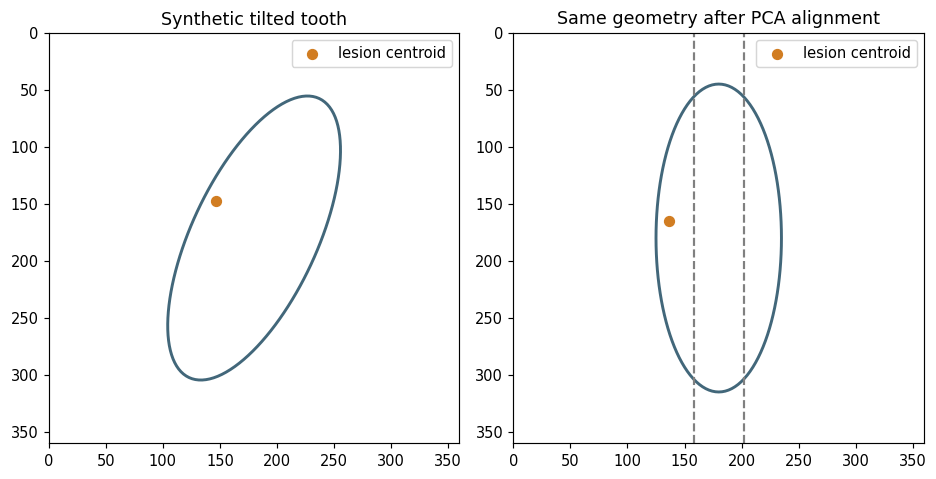

In [19]:
SURFACE_CONFIG=dict(left_bound=0.30,right_bound=0.70,max_tilt_degrees=45.0)
PREDICT_CONFIG=dict(imgsz=640,conf=0.25,iou=0.50,rect=True,retina_masks=False,
                    max_det=300,half=False,device=TRAIN_DEVICE,verbose=False)
display(pd.DataFrame([
 {"parameter":"lesion confidence","value":0.25,"purpose":"Operational filter, not a GT-match criterion."},
 {"parameter":"lesion NMS IoU","value":0.50,"purpose":"Suppress overlapping predicted detections."},
 {"parameter":"surface left/right bounds","value":"0.30 / 0.70","purpose":"Deterministic aligned-x surface zones."},
 {"parameter":"maximum tilt","value":"45 degrees","purpose":"Shared PCA clamps larger rotation to zero."},
 {"parameter":"mask resolution","value":"retina_masks=False","purpose":"Matches baseline prediction setting."},
 {"parameter":"input size","value":640,"purpose":"YOLO letterbox target, explicit rather than inherited."},
]))
# A synthetic geometry example; it is not a model prediction or an accuracy estimate.
t=np.linspace(0,2*np.pi,120,endpoint=False)
base=np.column_stack([55*np.cos(t),135*np.sin(t)])
center=np.array([180.,180.]);theta=np.deg2rad(25.)
R=np.array([[np.cos(theta),-np.sin(theta)],[np.sin(theta),np.cos(theta)]])
tooth=base@R.T+center
lesion=np.array([-44.,-15.])@R.T+center
c,angle,clamped=perform_pca(tooth.tolist(),26)
Q=np.array([[np.cos(angle),-np.sin(angle)],[np.sin(angle),np.cos(angle)]])
aligned=(tooth-c)@Q.T+c;aligned_lesion=(lesion-c)@Q.T+c
fig,axes=plt.subplots(1,2,figsize=(9,5))
for ax,poly,point,title in zip(axes,[tooth,aligned],[lesion,aligned_lesion],
                              ["Synthetic tilted tooth","Same geometry after PCA alignment"]):
    ax.add_patch(PolygonPatch(poly,fill=False,edgecolor="#42677A",linewidth=2))
    ax.scatter(*point,color="#D17D22",s=45,label="lesion centroid")
    ax.set(xlim=(0,360),ylim=(360,0),aspect="equal",title=title)
    ax.legend()
xmin,xmax=aligned[:,0].min(),aligned[:,0].max()
for fraction in (0.30,0.70):
    axes[1].axvline(xmin+fraction*(xmax-xmin),color="gray",linestyle="--")
plt.tight_layout()
print("Alignment angle:",round(np.rad2deg(angle),2),"degrees | clamped:",clamped)
display(pd.DataFrame([{"fdi":fdi,**classify_lesion_surface(
    fdi,tooth.tolist(),lesion,**{k:SURFACE_CONFIG[k] for k in ("left_bound","right_bound")})}
    for fdi in (16,26)]))

In [20]:
MODEL_CACHE={}
def load_inference_bundle(checkpoint_path):
    require_ml_environment(require_crop=True)
    from ultralytics import YOLO
    if Path(checkpoint_path).resolve()==PINNED_CARIES.resolve():
        assert sha256_file(checkpoint_path)==MODEL_VERSIONS["caries_detector"]["sha256"]
    from app.pipeline.pca_alignment import MAX_TILT_DEG
    if not 0<=SURFACE_CONFIG["left_bound"]<SURFACE_CONFIG["right_bound"]<=1:
        raise ValueError("Surface bounds must satisfy 0 <= left < right <= 1.")
    assert SURFACE_CONFIG["max_tilt_degrees"]==MAX_TILT_DEG, "PCA limit is fixed in shared code."
    key=(str(Path(checkpoint_path).resolve()),sha256_file(checkpoint_path),
         str(TRAIN_DEVICE),json.dumps(PREP,sort_keys=True),json.dumps(PREDICT_CONFIG,sort_keys=True))
    if key not in MODEL_CACHE:
        if PREP["preserve_pad"]!=15:
            raise ValueError("Shared run_stage1 fixes suppression preserve_pad=15. Keep parity or change shared code explicitly.")
        tooth_models=load_tooth_models()
        caries=YOLO(str(checkpoint_path))
        if list(caries.names.values())!=["caries"]:
            raise ValueError(f"Expected one class named caries, found {caries.names}")
        MODEL_CACHE[key]={**tooth_models,"caries":ExplicitYOLO(caries,**PREDICT_CONFIG)}
    return MODEL_CACHE[key]

def predict_panorama(image_path,checkpoint_path=None,confidence=None):
    # Image-only inference: this function never opens XML or reads target labels.
    checkpoint_path=Path(checkpoint_path or EVAL_CHECKPOINT)
    conf=PREDICT_CONFIG["conf"] if confidence is None else float(confidence)
    if not 0<=conf<=1:raise ValueError("Confidence must be in [0,1].")
    models=load_inference_bundle(checkpoint_path)
    started=time.perf_counter()
    detections,image=run_stage1(
        str(image_path),models,detection_threshold=PREP["pano_conf"],
        caries_conf=conf,caries_iou=PREDICT_CONFIG["iou"],
        crop_pad=PREP["crop_pad"],dedupe_iou=PREP["dedupe_iou"],
        suppress_neighbours=PREP["suppress_neighbours"])
    teeth=[]
    for det in detections:
        surfaces=findings_for_lesions(det.fdi,det.tooth_polygon,det.caries_lesions,
                                      left_bound=SURFACE_CONFIG["left_bound"],
                                      right_bound=SURFACE_CONFIG["right_bound"])
        lesions=[]
        for item,encoded in zip(det.caries_lesions,encode_caries_lesions(det.caries_lesions)):
            surface=classify_lesion_surface(det.fdi,det.tooth_polygon,item.centroid,
                                           left_bound=SURFACE_CONFIG["left_bound"],
                                           right_bound=SURFACE_CONFIG["right_bound"])
            lesions.append({**encoded,"surface":surface["name"],"x_rel":surface.get("x_rel")})
        teeth.append(dict(fdi=det.fdi,tooth_confidence=det.pano_confidence,
                          mask_source=det.mask_source,tooth_polygon=det.tooth_polygon,
                          surfaces=surfaces,lesions=lesions))
    result=dict(meta=dict(image_path=str(image_path),image_size=dict(width=int(image.shape[1]),height=int(image.shape[0])),
                          checkpoint=str(checkpoint_path),checkpoint_sha256=sha256_file(checkpoint_path),
                          device=str(next(models["caries"].model.model.parameters()).device),
                          confidence_threshold=conf,image_sha256=sha256_file(image_path),
                          environment=ENVIRONMENT,prep=dict(PREP),
                          predict_config={**PREDICT_CONFIG,"conf":conf},
                          surface_config=dict(SURFACE_CONFIG),
                          tooth_model_sha256={role:sha256_file(WEIGHTS_DIR/MODEL_VERSIONS[role]["filename"])
                                              for role in ("pano_detector","crop_segmenter")},
                          elapsed_seconds=time.perf_counter()-started,
                          tooth_count=len(teeth),lesion_count=sum(len(t["lesions"]) for t in teeth),
                          source_hashes=SOURCE_HASHES),teeth=teeth)
    return image,result,detections

## 07. Evaluation A: model quality on saved tooth crops
Use **YOLO.val()** on the validation crop split to measure box and mask quality. The checkpoint is fixed before evaluation.

For a matching rule, $P=TP/(TP+FP)$, $R=TP/(TP+FN)$, and $F1=2PR/(P+R)$.
Mask IoU is intersection area divided by union area. AP integrates a precision–recall curve over confidence ranking:
- mAP50 uses a GT-match IoU threshold of 0.50.
- mAP50–95 averages IoU thresholds 0.50, 0.55, ..., 0.95.
- With one class, the class average contains only caries.
- YOLO's reported precision/recall summarize its validator's operating-point choice; they are not necessarily values at production confidence 0.25.

**Keep three IoUs separate:** NMS IoU suppresses overlapping predictions; evaluation-match IoU defines a correct localization; mAP averages localization thresholds. A segmentation IoU metric is also not the same as a dataset-level mean pixel IoU.

Crop validation excludes tooth-detection failures and lesions absent from saved crops. It is therefore only one part of system evaluation.
**Version-specific validation behavior (8.4.175):** standalone validation below requests FP32 and batch 16. The training validator doubles the training batch for segmentation (16 → 32) and uses FP16 on GPU when trainer AMP is enabled. With rectangular batching, changing the batch size can change batch padding and predictions. In this version, enabling save_json or save_txt also selects a different mask-decoding function. Keep these settings fixed for a checkpoint comparison; the final verification appendix measures the batch/precision effect.


In [21]:
VAL_CONFIG=dict(imgsz=640,batch=16,device=TRAIN_DEVICE,workers=0,
                conf=0.001,iou=0.70,max_det=300,rect=True,half=False,
                retina_masks=False,plots=True,save_json=False,save_txt=False,split="val",
                project=str(EXPERIMENT_ROOT/"evaluation"),name="crop_validation",exist_ok=False)
VAL_MEANING={
 "imgsz":"Target input size for validation letterboxing.",
 "batch":"Images grouped per inference batch; batching can affect letterbox shapes.",
 "device":"Explicit evaluation device.",
 "workers":"0 avoids worker issues in interactive environments.",
 "conf":"Low collection threshold for AP ranking; not clinical threshold.",
 "iou":"NMS IoU, not GT localization-match threshold.",
 "max_det":"Maximum predictions retained per crop.",
 "rect":"Aspect-preserving rectangular validation batching.",
 "half":"False requests full precision for a controlled baseline.",
 "retina_masks":"Prediction flag; the inspected segmentation validator selects its decoder via export flags.",
 "plots":"Save standard validator figures.",
 "save_json":"False keeps the baseline mask decoder; enabling JSON also changes decoder in version 8.4.175.",
 "save_txt":"False keeps the baseline mask decoder; TXT export also switches decoder in version 8.4.175.",
 "split":"Use val directories from the runtime YAML.",
 "project":"New evaluation output root.",
 "name":"New run name.",
 "exist_ok":"False to avoid overwriting a previous evaluation."}
display(pd.DataFrame([dict(parameter=k,value=str(v),meaning=VAL_MEANING[k])
                      for k,v in VAL_CONFIG.items()]))
print("Selected dataset stored data.yaml:")
print((DATASET/"data.yaml").read_text())
print("Runtime data spec uses the absolute current-machine path:",local_data_spec(DATASET))

,parameter,value,meaning
0,imgsz,640,Target input size for validation letterboxing.
1,batch,16,Images grouped per inference batch; batching can affect letterbox shapes.
2,device,0,Explicit evaluation device.
3,workers,0,0 avoids worker issues in interactive environments.
4,conf,0.001,Low collection threshold for AP ranking; not clinical threshold.
5,iou,0.7,"NMS IoU, not GT localization-match threshold."
6,max_det,300,Maximum predictions retained per crop.
7,rect,True,Aspect-preserving rectangular validation batching.
8,half,False,False requests full precision for a controlled baseline.
9,retina_masks,False,Prediction flag; the inspected segmentation validator selects its decoder via export flags.


Selected dataset stored data.yaml:
path: /out/caries_crop_v1
train: images/train
val: images/val
names:
- caries

Runtime data spec uses the absolute current-machine path: {'path': 'D:\\Mahidol University\\SP\\dental-caries-detection\\ml-service\\datasets\\caries_crop_v1', 'train': 'images/train', 'val': 'images/val', 'names': ['caries']}


In [22]:
# Saved evidence is explicitly labelled; a fresh result never impersonates a historical run.
if FLAGS["RUN_CROP_EVALUATION"]:
    require_ml_environment()
    from ultralytics import YOLO
    with tempfile.TemporaryDirectory(prefix="caries_val_") as folder:
        data_path=Path(folder)/"data.yaml"
        data_path.write_text(yaml.safe_dump(local_data_spec(DATASET)),encoding="utf-8")
        validator_model=YOLO(str(EVAL_CHECKPOINT))
        validation=validator_model.val(data=str(data_path),**VAL_CONFIG)
    crop_evaluation=dict(evidence="new notebook evaluation",checkpoint=str(EVAL_CHECKPOINT),
                          checkpoint_sha256=sha256_file(EVAL_CHECKPOINT),config=VAL_CONFIG,
                          dataset=str(DATASET),environment=ENVIRONMENT,
                          metrics=validation.results_dict,speed=validation.speed)
    EXPERIMENT_ROOT.mkdir(parents=True,exist_ok=True)
    (EXPERIMENT_ROOT/"crop_evaluation.json").write_text(
        json.dumps(crop_evaluation,indent=2,default=str),encoding="utf-8")
else:
    crop_evaluation=json.loads((RECORDED_RESULTS/"validation-20261029.json").read_text())
    crop_evaluation["evidence"]="recorded v1 validation from 29 October 2026"
    print("No fresh model evaluation was executed.")
    if Path(EVAL_CHECKPOINT).resolve()!=PINNED_CARIES.resolve() or DATASET!=REFERENCE_DATASET:
        print("These historical v1 metrics do NOT evaluate the selected candidate.")
print("Evidence:",crop_evaluation["evidence"])
if not FLAGS["RUN_CROP_EVALUATION"]:
    print("Recorded population: v1 validation, 626 crops / 354 lesion instances.")
display(pd.Series(crop_evaluation["metrics"],name="score").to_frame())

No fresh model evaluation was executed.
Evidence: recorded v1 validation from 29 October 2026
Recorded population: v1 validation, 626 crops / 354 lesion instances.


,score
metrics/precision(B),0.588427
metrics/recall(B),0.593220
metrics/mAP50(B),0.563264
metrics/mAP50-95(B),0.212173
metrics/precision(M),0.537279
metrics/recall(M),0.508405
metrics/mAP50(M),0.484282
metrics/mAP50-95(M),0.157320
fitness,0.369494


### Recorded crop-validation result
The 29 October recheck used 626 crops and 354 instances:
- mask mAP50 **0.48428**, mask mAP50–95 **0.15732**;
- mask precision **0.53728**, mask recall **0.50840**;
- box mAP50 **0.56326**, box mAP50–95 **0.21217**.

These are recorded validation scores. Embedded training metadata has mask mAP50 **0.49127**. The final verification reran the pinned checkpoint with Ultralytics 8.4.175: FP32/batch 16 gave **0.48428**, while FP16/batch 32 gave **0.49108**. Matching the training validator's precision and batch therefore brought mAP50 close to the training-time value. The small residual and other metrics have not been fully attributed across the original and current environments. Compare checkpoints with the same precision, batch, mask decoder, data, and software.


## 08. Evaluation B: the complete panorama pipeline

**Question:** When all detected teeth are examined, how many XML lesions are found, missed, or added?

The evaluation unit is a lesion instance on a particular FDI. An accepted match requires the same FDI and polygon-mask IoU ≥ **0.30**. This more permissive localization rule differs from crop mAP50 and is not a substitute for mAP.

The implementation below is copied from the project's evaluator to make the matching rule visible. It rasterizes each polygon pair in their joint local box, then greedily visits GT lesions and selects the highest-IoU available prediction. The original protocol is **GT-first greedy**, not confidence-ordered AP matching. In crowded examples, matching can depend on GT order. Compare alternate protocols separately rather than silently changing the baseline.

Labels are used only after image-only prediction for scoring. All XML lesions in each validation case remain in the denominator, including ones lost during crop preparation.

In [23]:
# Baseline matching implementation, inlined from scripts/evaluate_caries_pipeline.py.

def _bbox(polygon: np.ndarray) -> tuple[float, float, float, float]:
    return (
        float(polygon[:, 0].min()),
        float(polygon[:, 1].min()),
        float(polygon[:, 0].max()),
        float(polygon[:, 1].max()),
    )

def _bbox_iou(a: tuple, b: tuple) -> float:
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    if inter <= 0:
        return 0.0
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

def mask_iou(poly_a, poly_b, bbox_a=None, bbox_b=None) -> float:
    """IoU of two pano-space polygons, rasterized in their local union bbox."""
    a = np.asarray(poly_a, dtype=np.float64).reshape(-1, 2)
    b = np.asarray(poly_b, dtype=np.float64).reshape(-1, 2)
    if len(a) < 3 or len(b) < 3:
        return 0.0
    ba = bbox_a or _bbox(a)
    bb = bbox_b or _bbox(b)
    if _bbox_iou(ba, bb) <= 0.0:
        return 0.0

    x1 = int(np.floor(min(ba[0], bb[0]))) - 1
    y1 = int(np.floor(min(ba[1], bb[1]))) - 1
    x2 = int(np.ceil(max(ba[2], bb[2]))) + 1
    y2 = int(np.ceil(max(ba[3], bb[3]))) + 1
    w, h = x2 - x1, y2 - y1
    if w <= 0 or h <= 0:
        return 0.0

    def raster(poly: np.ndarray) -> np.ndarray:
        m = np.zeros((h, w), dtype=np.uint8)
        pts = np.round(poly - [x1, y1]).astype(np.int32).reshape(-1, 1, 2)
        cv2.fillPoly(m, [pts], 1)
        return m

    ma, mb = raster(a), raster(b)
    union = int(np.logical_or(ma, mb).sum())
    if union == 0:
        return 0.0
    return float(np.logical_and(ma, mb).sum()) / union

def _match(
    gt_by_fdi: dict[int, list],
    pred_by_fdi: dict[int, list],
    match_iou: float,
) -> list[tuple]:
    """Greedy per-FDI matching.  Returns matched ``(gt, pred, iou)`` pairs."""
    pairs: list[tuple] = []
    for fdi in sorted(set(gt_by_fdi) | set(pred_by_fdi)):
        gts = gt_by_fdi.get(fdi, [])
        preds = pred_by_fdi.get(fdi, [])
        used: set[int] = set()
        for gt in gts:
            best_i, best_iou = -1, match_iou
            for i, pred in enumerate(preds):
                if i in used:
                    continue
                if _bbox_iou(gt["bbox"], pred["bbox"]) <= 0.0:
                    continue
                iou = mask_iou(gt["polygon"], pred["polygon"], gt["bbox"], pred["bbox"])
                if iou >= best_iou:
                    best_i, best_iou = i, iou
            if best_i >= 0:
                used.add(best_i)
                pairs.append((gt, preds[best_i], best_iou))
    return pairs

def _counts(gt_by_fdi: dict[int, list], pred_by_fdi: dict[int, list], pairs: list) -> tuple[int, int, int]:
    n_gt = sum(len(v) for v in gt_by_fdi.values())
    n_pred = sum(len(v) for v in pred_by_fdi.values())
    tp = len(pairs)
    return tp, n_pred - tp, n_gt - tp

In [24]:
FULL_EVAL_CONFIG=dict(collect_conf=0.01,match_iou=0.30,case_limit=0,
                      thresholds=[0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.50,0.60])
if not (0<FULL_EVAL_CONFIG["match_iou"]<=1):
    raise ValueError("match_iou must be in (0,1].")
if not FULL_EVAL_CONFIG["thresholds"] or any(
    not FULL_EVAL_CONFIG["collect_conf"]<=t<=1 for t in FULL_EVAL_CONFIG["thresholds"]):
    raise ValueError("Every sweep threshold must be at least collect_conf and at most 1.")
if FULL_EVAL_CONFIG["case_limit"]<0:raise ValueError("case_limit must be nonnegative.")
display(pd.DataFrame([
 dict(parameter="collect_conf",value=str(FULL_EVAL_CONFIG["collect_conf"]),
      meaning="Keep low-confidence predictions for one offline sweep."),
 dict(parameter="match_iou",value=str(FULL_EVAL_CONFIG["match_iou"]),
      meaning="GT lesion-mask overlap required on the same FDI."),
 dict(parameter="NMS IoU",value=str(PREDICT_CONFIG["iou"]),meaning="Prediction suppression; not GT matching."),
 dict(parameter="thresholds",value=str(FULL_EVAL_CONFIG["thresholds"]),meaning="Operating confidence values."),
 dict(parameter="case_limit",value=str(FULL_EVAL_CONFIG["case_limit"]),
      meaning="Zero means all validation cases, not all 500 cases."),
 dict(parameter="surface bounds",value=str([SURFACE_CONFIG["left_bound"],SURFACE_CONFIG["right_bound"]]),
      meaning="Fixed geometry rule, evaluated after lesion match."),
]))
ACTIVE_MANIFEST=json.loads((DATASET/"manifest.json").read_text(encoding="utf-8"))
FULL_VAL_IDS=sorted(int(cid) for cid,info in ACTIVE_MANIFEST["cases"].items() if info["split"]=="val")
if not FULL_VAL_IDS:raise ValueError("The active manifest has no validation cases.")
missing_xml_cases=set(FULL_VAL_IDS)-set(XML_BY_CASE)
if missing_xml_cases:raise ValueError(f"Validation case folders missing: {sorted(missing_xml_cases)}")
print("Validation cases:",len(FULL_VAL_IDS),
      "| XML lesions:",sum(len(XML_BY_CASE[cid]) for cid in FULL_VAL_IDS),
      "| train cases excluded:",sum(info["split"]=="train" for info in ACTIVE_MANIFEST["cases"].values()))


,parameter,value,meaning
0,collect_conf,0.01,Keep low-confidence predictions for one offline sweep.
1,match_iou,0.3,GT lesion-mask overlap required on the same FDI.
2,NMS IoU,0.5,Prediction suppression; not GT matching.
3,thresholds,"[0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6]",Operating confidence values.
4,case_limit,0,"Zero means all validation cases, not all 500 cases."
5,surface bounds,"[0.3, 0.7]","Fixed geometry rule, evaluated after lesion match."


Validation cases: 100 | XML lesions: 373 | train cases excluded: 400


In [25]:
def collect_full_predictions():
    records=[]
    selected_ids=FULL_VAL_IDS
    if FULL_EVAL_CONFIG["case_limit"]>0:selected_ids=selected_ids[:FULL_EVAL_CONFIG["case_limit"]]
    for index,cid in enumerate(selected_ids,1):
        image_path=IMAGE_ROOT/f"case {cid}"/f"case_{cid}.png"
        if not image_path.exists():raise FileNotFoundError(image_path)
        # predict_panorama never reads annotations.
        _,result,detections=predict_panorama(
            image_path,EVAL_CHECKPOINT,FULL_EVAL_CONFIG["collect_conf"])
        gts=defaultdict(list);preds=defaultdict(list)
        for lesion in XML_BY_CASE[cid]:
            poly=np.asarray(lesion.polygon)
            if len(poly)>=3:
                gts[lesion.fdi].append(dict(fdi=lesion.fdi,surface=lesion.surface,
                                           polygon=poly.tolist(),bbox=_bbox(poly)))
        for det in detections:
            for lesion in det.caries_lesions:
                surface=classify_lesion_surface(
                    det.fdi,det.tooth_polygon,lesion.centroid,
                    left_bound=SURFACE_CONFIG["left_bound"],right_bound=SURFACE_CONFIG["right_bound"])
                poly=np.asarray(lesion.polygon)
                if len(poly)<3:continue
                preds[det.fdi].append(dict(fdi=det.fdi,confidence=float(lesion.confidence),
                                          surface=surface["name"],polygon=poly.tolist(),
                                          bbox=_bbox(poly),centroid=list(lesion.centroid)))
        records.append(dict(case=cid,gt_by_fdi=dict(gts),pred_by_fdi=dict(preds),
                            teeth=len(detections),
                            refined=sum(d.mask_source=="crop_seg" for d in detections),
                            seconds=result["meta"]["elapsed_seconds"]))
        if index%10==0:print(f"Evaluated {index}/{len(selected_ids)} panoramas")
    return records

def prf(tp,fp,fn):
    precision=tp/(tp+fp) if tp+fp else 0.0
    recall=tp/(tp+fn) if tp+fn else 0.0
    f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0
    return precision,recall,f1

def score_full_records(records,threshold,match_iou=None):
    if not records:raise ValueError("Cannot score an empty case collection.")
    match_iou=FULL_EVAL_CONFIG["match_iou"] if match_iou is None else match_iou
    per_case=[];confusion=Counter()
    for record in records:
        gts={int(fdi):items for fdi,items in record["gt_by_fdi"].items()}
        preds={int(fdi):[x for x in items if x["confidence"]>=threshold]
               for fdi,items in record["pred_by_fdi"].items()}
        pairs=_match(gts,preds,match_iou)
        tp,fp,fn=_counts(gts,preds,pairs)
        correct=0
        for gt,pred,iou in pairs:
            confusion[(gt["surface"],pred["surface"])]+=1
            correct+=int(gt["surface"]==pred["surface"])
        per_case.append(dict(case=record["case"],tp=tp,fp=fp,fn=fn,surface_correct=correct))
    sums={k:sum(c[k] for c in per_case) for k in ("tp","fp","fn","surface_correct")}
    p,r,f1=prf(sums["tp"],sums["fp"],sums["fn"])
    summary=dict(threshold=threshold,tp=sums["tp"],fp=sums["fp"],fn=sums["fn"],
                 precision=p,recall=r,f1=f1,surface_n=sums["tp"],
                 surface_accuracy=sums["surface_correct"]/sums["tp"] if sums["tp"] else None)
    return summary,confusion,per_case

Evidence: recorded v1 full-pipeline validation, not rerun in this execution
Evaluated cases: 100 | evaluation match IoU: 0.3


,threshold,tp,fp,fn,precision,recall,f1,surface_accuracy,surface_n
0,0.05,302,982,71,0.2352,0.8097,0.3645,0.8907,302
1,0.10,286,600,87,0.3228,0.7668,0.4543,0.8916,286
2,0.15,270,400,103,0.4030,0.7239,0.5177,0.8852,270
3,0.20,258,309,115,0.4550,0.6917,0.5489,0.8876,258
4,0.25,246,222,127,0.5256,0.6595,0.5850,0.8821,246
5,0.30,220,168,153,0.5670,0.5898,0.5782,0.8682,220
6,0.35,200,118,173,0.6289,0.5362,0.5789,0.8650,200
7,0.40,158,83,215,0.6556,0.4236,0.5147,0.8418,158
8,0.50,105,36,268,0.7447,0.2815,0.4086,0.8095,105
9,0.60,67,23,306,0.7444,0.1796,0.2894,0.7761,67


Selected operating point on validation: {'threshold': 0.25, 'tp': 246, 'fp': 222, 'fn': 127, 'precision': 0.5256, 'recall': 0.6595, 'f1': 0.585, 'surface_accuracy': 0.8821, 'surface_n': 246}


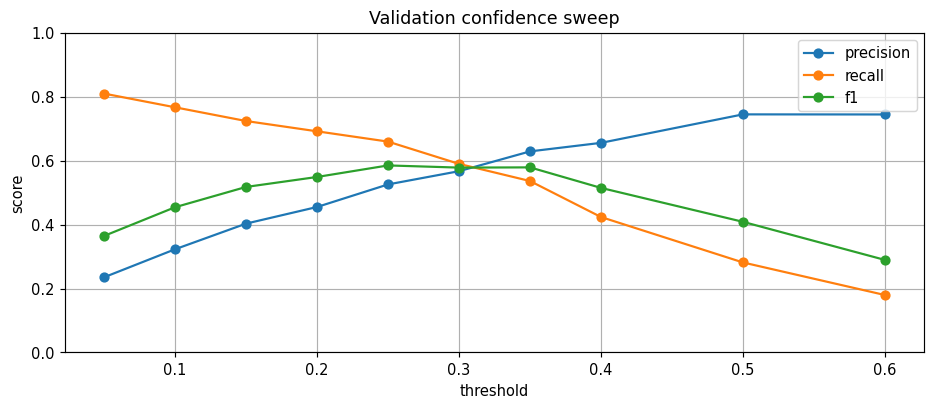

In [26]:
full_records=None
if FLAGS["RUN_FULL_EVALUATION"]:
    full_records=collect_full_predictions()
    sweep=[score_full_records(full_records,t)[0] for t in FULL_EVAL_CONFIG["thresholds"]]
    selected=max(sweep,key=lambda row:(row["f1"],row["recall"]))
    _,confusion,scored_cases=score_full_records(full_records,selected["threshold"])
    full_evaluation=dict(evidence="new notebook full-pipeline validation",val_cases=len(full_records),
                          checkpoint=str(EVAL_CHECKPOINT),checkpoint_sha256=sha256_file(EVAL_CHECKPOINT),
                          dataset=str(DATASET),dataset_manifest_sha256=sha256_file(DATASET/"manifest.json"),
                          case_ids=[record["case"] for record in full_records],
                          match_iou=FULL_EVAL_CONFIG["match_iou"],
                          config=dict(FULL_EVAL_CONFIG),predict_config=dict(PREDICT_CONFIG),
                          prep=dict(PREP),surface_config=dict(SURFACE_CONFIG),
                          thresholds=sweep,selected=selected,per_case=scored_cases,
                          surface_confusion={f"{a}->{b}":v for (a,b),v in confusion.items()},
                          environment=ENVIRONMENT,source_hashes=SOURCE_HASHES)
    EXPERIMENT_ROOT.mkdir(parents=True,exist_ok=True)
    full_output_dir=EXPERIMENT_ROOT/"full_evaluation"/datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    full_output_dir.mkdir(parents=True,exist_ok=False)
    (full_output_dir/"full_predictions.json").write_text(json.dumps(full_records,indent=2),encoding="utf-8")
    (full_output_dir/"full_evaluation.json").write_text(
        json.dumps(full_evaluation,indent=2,default=str),encoding="utf-8")
    print("New evaluation artifacts:",full_output_dir)
else:
    full_evaluation=json.loads((SERVICE/"runs"/"caries_eval.json").read_text())
    full_evaluation["evidence"]="recorded v1 full-pipeline validation, not rerun in this execution"
    if Path(EVAL_CHECKPOINT).resolve()!=PINNED_CARIES.resolve() or DATASET!=REFERENCE_DATASET:
        print("These historical v1 metrics do NOT evaluate the selected candidate.")
print("Evidence:",full_evaluation["evidence"])
print("Evaluated cases:",full_evaluation["val_cases"],
      "| evaluation match IoU:",full_evaluation["match_iou"])
threshold_df=pd.DataFrame(full_evaluation["thresholds"])
display(threshold_df)
best_row=full_evaluation["selected"]
print("Selected operating point on validation:",best_row)
ax=threshold_df.plot(x="threshold",y=["precision","recall","f1"],marker="o",
                     figsize=(9,4),title="Validation confidence sweep",ylim=(0,1),grid=True)
ax.set_ylabel("score");plt.tight_layout()

### Interpret the full-pipeline result
The saved v1 result at confidence **0.25** is TP=246, FP=222, FN=127:
- precision **52.56%**, recall **65.95%**, lesion F1 **58.50%**;
- GT lesions **373**; predicted lesions **468**.

A prediction on the wrong FDI cannot match the GT and creates FP/FN. Equal lesion counts per case do not prove correct localization or tooth ownership.

The confidence sweep chooses the best observed validation F1, so this split has also been used for calibration. It is not an independent test. The saved JSON contains aggregate counts and per-case totals but not every prediction mask. You must enable fresh full evaluation to rematch masks, change the matching rule, or compute valid per-case uncertainty from TP/FP/FN.

## 09. Evaluation C: surface agreement and the joint task
Surface agreement is conditional on successful lesion matching:
$$A_{surface}=\frac{\text{matched lesions with correct surface}}{\text{matched lesions}}.$$
The recorded **88.21%** excludes 127 missed lesions and 222 unmatched predictions.

For the stricter joint task, count a prediction as correct only if lesion, FDI, and surface are correct. A matched wrong-surface prediction contributes both a joint FP and a joint FN. This is a clearly defined joint count derived from the same lesion matches, not a replacement for a dedicated clinical endpoint.

,occlusal,mesial,distal
GT occlusal,30,5,10
GT mesial,0,78,0
GT distal,13,1,109


,task,tp,fp,fn,precision,recall,f1
0,Lesion localization on same FDI,246,222,127,0.525600,0.659500,0.585000
1,Lesion + FDI + surface,217,251,156,0.463675,0.581769,0.516052


Surface agreement denominator: 246 | correct: 217


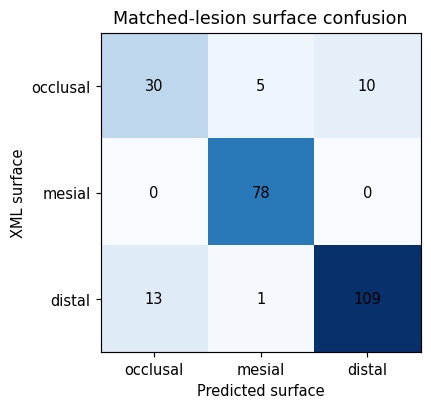

In [27]:
labels=["occlusal","mesial","distal"]
surface_confusion=full_evaluation["surface_confusion"]
matrix=np.array([[surface_confusion.get(f"{a}->{b}",0) for b in labels] for a in labels])
assert all(key in {f"{a}->{b}" for a in labels for b in labels}
           for key in surface_confusion),"Unknown surface labels must be reviewed."
assert int(matrix.sum())==int(best_row["tp"]),"Surface confusion must contain one entry per matched lesion."
display(pd.DataFrame(matrix,index=[f"GT {x}" for x in labels],columns=labels))
fig,ax=plt.subplots(figsize=(5,4))
ax.imshow(matrix,cmap="Blues")
for (i,j),value in np.ndenumerate(matrix):ax.text(j,i,str(value),ha="center",va="center")
ax.set(xticks=range(3),yticks=range(3),xticklabels=labels,yticklabels=labels,
       xlabel="Predicted surface",ylabel="XML surface",title="Matched-lesion surface confusion")
plt.tight_layout()
correct=sum(v for key,v in surface_confusion.items() if key.split("->")[0]==key.split("->")[1])
assert correct==int(np.trace(matrix))
wrong_surface=best_row["tp"]-correct
joint_tp=correct;joint_fp=best_row["fp"]+wrong_surface;joint_fn=best_row["fn"]+wrong_surface
joint_p,joint_r,joint_f1=prf(joint_tp,joint_fp,joint_fn)
display(pd.DataFrame([
 dict(task="Lesion localization on same FDI",tp=best_row["tp"],fp=best_row["fp"],fn=best_row["fn"],
      precision=best_row["precision"],recall=best_row["recall"],f1=best_row["f1"]),
 dict(task="Lesion + FDI + surface",tp=joint_tp,fp=joint_fp,fn=joint_fn,
      precision=joint_p,recall=joint_r,f1=joint_f1)]))
print("Surface agreement denominator:",best_row["tp"],"| correct:",correct)

### Surface-classification report in the requested format

This report is calculated from **matched lesion pairs only** at the selected confidence threshold and mask-IoU rule. It answers: when the pipeline found a lesion and matched it to XML, did the geometry assign the correct surface? Consequently, Total Samples here is the number of matched pairs, not all XML lesions. Missed lesions and unmatched predictions are excluded from this multiclass matrix and remain visible in the separate end-to-end TP/FP/FN report above.

The surface stage has three outputs—Mesial, Occlusal, and Distal—so this report uses those three classes. It does not add an unsupported Other class. Accuracy and the classification report must not be presented as end-to-end caries-detection performance.

The summary Precision, Recall, and F1 Score use the **macro average** over three defined surface classes. The report also shows support-weighted averages. The historical RF example used a fourth Other class with zero GT support; including that zero-score class changes the macro average, so its values are not directly comparable to this three-class report. Accuracy is undefined if there are no matched lesions.


In [28]:
# Conditional multiclass evaluation: one sample per matched lesion pair.
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SURFACE_LABELS=["occlusal","mesial","distal"]

def surface_classification_metrics(counts,labels=SURFACE_LABELS):
    allowed={f"{a}->{b}" for a in labels for b in labels}
    if set(counts)-allowed:raise ValueError(f"Unexpected surface labels: {set(counts)-allowed}")
    y_true,y_pred=[],[]
    for key,count in counts.items():
        if count<0 or int(count)!=count:raise ValueError("Counts must be nonnegative integers.")
        actual,predicted=key.split("->")
        y_true.extend([actual]*int(count));y_pred.extend([predicted]*int(count))
    cm=confusion_matrix(y_true,y_pred,labels=labels)
    report=classification_report(y_true,y_pred,labels=labels,zero_division=0,output_dict=True)
    accuracy=accuracy_score(y_true,y_pred) if y_true else None
    return dict(n=len(y_true),accuracy=accuracy,precision=report["macro avg"]["precision"],
                recall=report["macro avg"]["recall"],f1=report["macro avg"]["f1-score"],
                confusion=cm,report=report)

surface_metrics=surface_classification_metrics(full_evaluation["surface_confusion"])
assert surface_metrics["n"]==best_row["tp"],"Classification support must equal matched-lesion TP."
print("Evaluation scope : matched lesion-surface pairs only")
print("Evidence         :",full_evaluation["evidence"])
print("Confidence       :",best_row["threshold"])
print("Mask IoU match   :",full_evaluation["match_iou"])
print(f"Total Samples    : {surface_metrics['n']}")
if surface_metrics["n"]:
    print(f"Accuracy         : {surface_metrics['accuracy']:.4f}")
    print(f"Precision (macro): {surface_metrics['precision']:.4f}")
    print(f"Recall    (macro): {surface_metrics['recall']:.4f}")
    print(f"F1 Score  (macro): {surface_metrics['f1']:.4f}")
else:
    print("Accuracy / macro scores: undefined because no lesions matched.")
print("\nConfusion Matrix (rows = actual XML, columns = predicted):")
display(pd.DataFrame(surface_metrics["confusion"],
                     index=[name.title() for name in SURFACE_LABELS],
                     columns=[name.title() for name in SURFACE_LABELS]))
report_rows={name.title():surface_metrics["report"][name] for name in SURFACE_LABELS}
report_rows.update({name:surface_metrics["report"][name] for name in ("macro avg","weighted avg")})
report_df=pd.DataFrame.from_dict(report_rows,orient="index")
report_df["support"]=report_df["support"].astype(int)
print("\nClassification Report:")
print(report_df.to_string(float_format=lambda v:f"{v:.4f}"))
print("Accuracy is correct matched surfaces / matched lesions.")
print("Macro averages give each of the three classes equal weight; weighted averages use class support.")
print("Missed lesions and unmatched predictions remain in the separate end-to-end detection report.")


Evaluation scope : matched lesion-surface pairs only
Evidence         : recorded v1 full-pipeline validation, not rerun in this execution
Confidence       : 0.25
Mask IoU match   : 0.3
Total Samples    : 246
Accuracy         : 0.8821
Precision (macro): 0.8474
Recall    (macro): 0.8509
F1 Score  (macro): 0.8485

Confusion Matrix (rows = actual XML, columns = predicted):


,Occlusal,Mesial,Distal
Occlusal,30,5,10
Mesial,0,78,0
Distal,13,1,109



Classification Report:
              precision  recall  f1-score  support
Occlusal         0.6977  0.6667    0.6818       45
Mesial           0.9286  1.0000    0.9630       78
Distal           0.9160  0.8862    0.9008      123
macro avg        0.8474  0.8509    0.8485      246
weighted avg     0.8800  0.8821    0.8805      246
Accuracy is correct matched surfaces / matched lesions.
Macro averages give each of the three classes equal weight; weighted averages use class support.
Missed lesions and unmatched predictions remain in the separate end-to-end detection report.


### Optional case-bootstrap uncertainty
Lesions within a case are correlated. Bootstrap whole cases, not independently shuffled lesions. This interval describes sampling variation in the evaluated cases; it does not remove validation-selection bias or annotation error. The historical summary lacks per-case TP/FP/FN, so no interval is fabricated for it.

In [29]:
def bootstrap_case_f1(per_case,draws=2000,seed=42):
    if not per_case or draws<=0:raise ValueError("Bootstrap needs cases and a positive draw count.")
    data=np.asarray([[r["tp"],r["fp"],r["fn"]] for r in per_case],dtype=float)
    rng=np.random.default_rng(seed);scores=[]
    for _ in range(draws):
        tp,fp,fn=data[rng.integers(0,len(data),len(data))].sum(axis=0)
        scores.append(prf(tp,fp,fn)[2])
    return np.quantile(scores,[0.025,0.5,0.975])
if full_records is not None:
    print("Case-bootstrap F1 [2.5%, 50%, 97.5%]:",
          bootstrap_case_f1(full_evaluation["per_case"]))
else:
    print("No interval: enable fresh full evaluation to retain per-case matched counts.")

No interval: enable fresh full evaluation to retain per-case matched counts.


## 10. Error analysis: what do individual failures show?
The saved offline audit contains cases 10, 20, and 42. Inspect refinement and detection separately. Correct tooth crops do not guarantee that the caries model finds the lesions.

The figure below is explicitly a **recorded centroid preview**: the saved spot-check JSON does not contain lesion polygons, so it cannot reconstruct predicted masks. The live interface later generates masks from the selected checkpoint. Do not present centroid markers as segmentation masks.

,case,teeth,refined,tp,fp,fn,identical_saved_crops,compared_crops
0,10,29,29,1,1,1,5,5
1,20,31,31,7,2,2,8,10
2,42,31,31,0,1,4,4,7


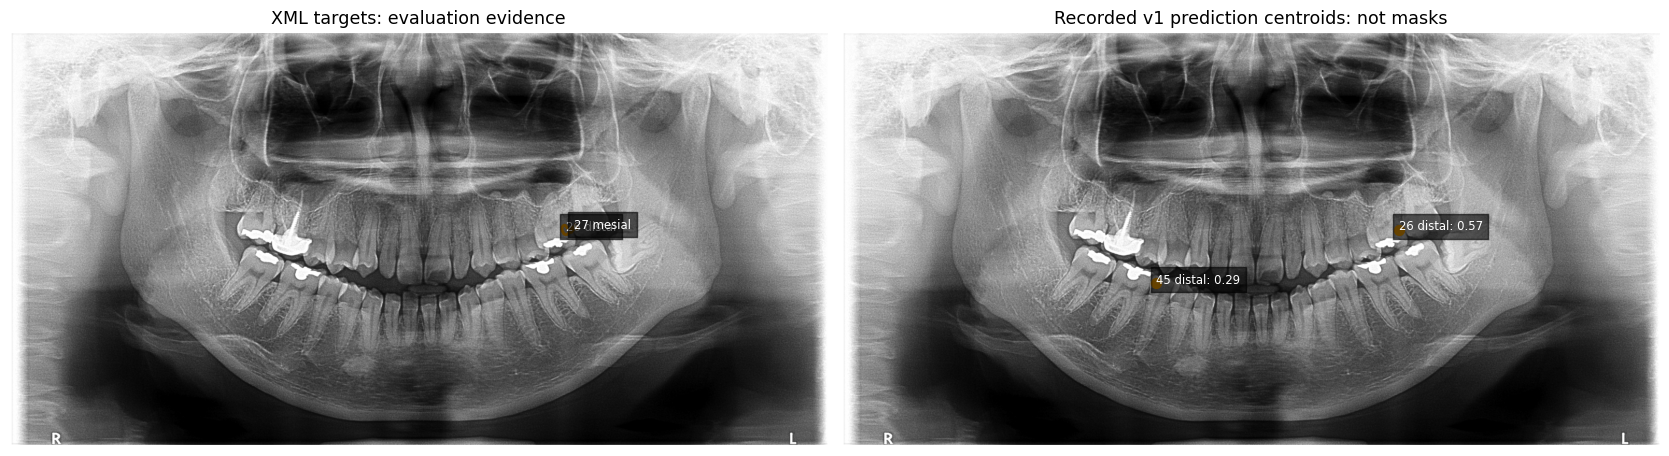

In [30]:
audit_path=RECORDED_RESULTS/"inference-parity-gpu-20261029.json"
saved_audit=json.loads(audit_path.read_text())
display(pd.DataFrame([
    dict(case=c["case"],teeth=c["teeth"],refined=c["refined"],
         tp=c["lesion_metrics"]["0.3"]["tp"],fp=c["lesion_metrics"]["0.3"]["fp"],
         fn=c["lesion_metrics"]["0.3"]["fn"],
         identical_saved_crops=sum(x["pixels_equal"] for x in c["crop_comparisons"]),
         compared_crops=len(c["crop_comparisons"]))
    for c in saved_audit["cases"]]))
saved_case=next(c for c in saved_audit["cases"] if c["case"]==EXAMPLE_CASE)
fig,axes=plt.subplots(1,2,figsize=(16,6))
for ax in axes:ax.imshow(cv2.cvtColor(example_image,cv2.COLOR_BGR2RGB));ax.axis("off")
for lesion in XML_BY_CASE[EXAMPLE_CASE]:
    axes[0].add_patch(PolygonPatch(lesion.polygon,fill=False,edgecolor="orange",linewidth=2))
    axes[0].text(*lesion.centroid,f"{lesion.fdi} {lesion.surface}",color="white",
                 bbox={"facecolor":"black","alpha":0.6},fontsize=8)
for pred in saved_case["predictions"]:
    axes[1].scatter(*pred["centroid"],s=45,color="orange")
    axes[1].text(*pred["centroid"],f'{pred["fdi"]} {pred["surface"]}: {pred["confidence"]:.2f}',
                 color="white",bbox={"facecolor":"black","alpha":0.6},fontsize=8)
axes[0].set_title("XML targets: evaluation evidence")
axes[1].set_title("Recorded v1 prediction centroids: not masks")
plt.tight_layout()

### Error review protocol
For each FP/FN, inspect original image, tooth box, refined mask, suppressed crop, predicted lesion mask, GT polygon, FDI, confidence, and match IoU.

Classify errors as upstream tooth miss, clipping/suppression loss, lesion miss, low confidence, wrong-tooth ownership, poor mask overlap, incomplete annotation, or surface-rule error. A FP on one FDI and a FN on another does not by itself prove an FDI swap. Case 10 has the correct FDI 27 crop but misses its lesion; FDI 45 is a separate false prediction.

A useful next hypothesis is that more representative negatives or reviewed hard negatives reduce false positives. Change one factor at a time, tune on a separate split, and compare on a fixed independent test set. Also stratify results by lesion size, quadrant, and surface.

## 11. Inference interface: upload/select → predict → overlay → inspect → export

The interface uses the selected checkpoint and image pixels only. It does not read XML, perform training, or call the live web service. The full evaluation loop calls the same predict_panorama() function.
The reported elapsed_seconds starts after model loading; the first button click can also spend time loading models.

- Choose a project image or upload PNG/JPEG.
- Review the checkpoint path and confidence threshold.
- Click **Run inference**. Tooth models load lazily; CPU refinement can take tens of seconds or longer.
- View tooth outlines, lesion-mask overlays, FDI/surface labels, and a lesion table.
- Inspect JSON and optionally export the result and overlay into this new experiment's interface folder.

The interface displays the highest lesion-detection confidence assigned to each heuristic surface as `Probability`. This is a raw model score, not a calibrated probability for the whole surface. A missing finding means no prediction survived this threshold; it does not establish a normal tooth.

### Verified working inference example: case 10

This is a **recorded execution of this notebook's predict_panorama(), plot_predictions(), lesion_table(), and service-result conversion**, run on 29 October 2026 in the project ML container. Environment: Python 3.10.22, PyTorch 2.4.1, Ultralytics 8.4.191, Detectron2 0.6, RTX 4080 Laptop GPU. Confidence threshold: 0.25.

The real run refined **29/29 teeth** and predicted **2 lesions**. The model returned lesion masks, not only centroids. The image below is embedded in this notebook and does not require an external preview file.

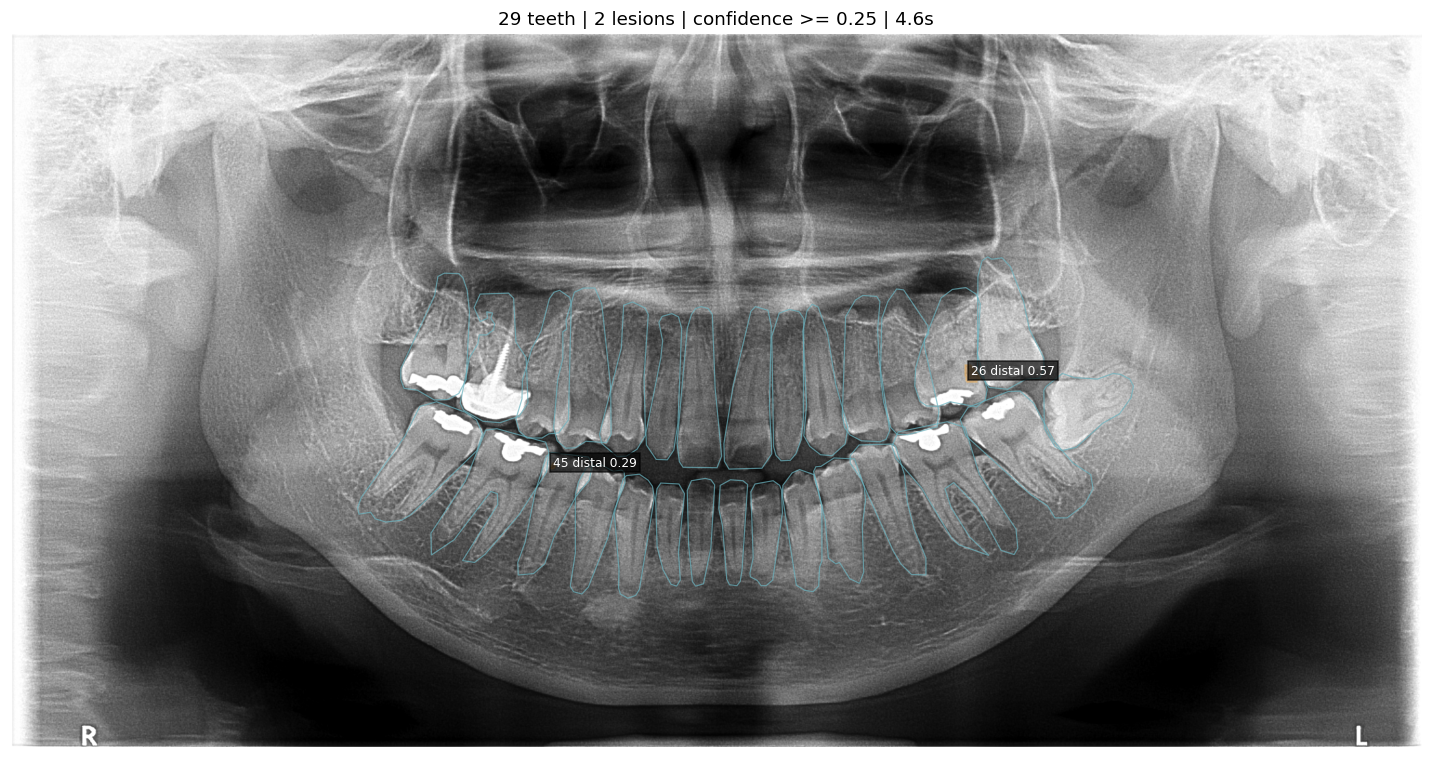

| Predicted FDI | Heuristic surface | Lesion confidence | Tooth mask source |
|---|---|---|---|
| 45 | distal | 0.2853 | crop_seg |
| 26 | distal | 0.5662 | crop_seg |

The same predictions scored TP=1, FP=1, FN=1 against case 10 XML at mask IoU ≥0.30. The image demonstrates working inference and export; it does not demonstrate perfect accuracy. Upload a new image or choose a case below and click Run inference for a new prediction.


In [31]:
from IPython.display import JSON

def lesion_table(result):
    rows=[]
    for tooth in result["teeth"]:
        for index,lesion in enumerate(tooth["lesions"],1):
            rows.append(dict(fdi=tooth["fdi"],lesion=index,surface=lesion["surface"],
                             lesion_confidence=lesion["confidence"],
                             tooth_confidence=tooth["tooth_confidence"],
                             mask_source=tooth["mask_source"],x_rel=lesion["x_rel"],
                             bbox_xywh=lesion["bbox"]))
    return pd.DataFrame(rows,columns=["fdi","lesion","surface","lesion_confidence",
                                     "tooth_confidence","mask_source","x_rel","bbox_xywh"])

def plot_predictions(image,result,show_teeth=True):
    fig,ax=plt.subplots(figsize=(16,7))
    ax.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB))
    for tooth in result["teeth"]:
        if show_teeth:
            ax.add_patch(PolygonPatch(tooth["tooth_polygon"],fill=False,edgecolor="#6DB3BF",
                                      linewidth=0.8,alpha=0.7))
        for lesion in tooth["lesions"]:
            ax.add_patch(PolygonPatch(lesion["mask"]["data"],closed=True,
                                      facecolor="#EA9C3B",edgecolor="#F2B55D",alpha=0.4))
            x,y=lesion["centroid"]
            ax.text(x,y,f'{tooth["fdi"]} {lesion["surface"]} {lesion["confidence"]:.2f}',
                    color="white",fontsize=8,
                    bbox={"facecolor":"black","alpha":0.65,"pad":2})
    meta=result["meta"]
    ax.set_title(f'{meta["tooth_count"]} teeth | {meta["lesion_count"]} lesions | '
                 f'confidence >= {meta["confidence_threshold"]:.2f} | '
                 f'{meta["elapsed_seconds"]:.1f}s')
    ax.axis("off");fig.tight_layout()
    return fig

def as_service_result(image,result,detections):
    # Convert the notebook research object into the existing raw ML-service contract.
    from app.pipeline.pca_alignment import run_stage2
    from app.pipeline.postprocess import build_tooth_result
    axes_by_fdi=run_stage2(detections);teeth=[]
    for index,det in enumerate(detections):
        axes=axes_by_fdi.get(det.fdi)
        axes_dict=(dict(major=list(axes.major),minor=list(axes.minor),
                        rotation_deg=axes.rotation_deg,clamped=axes.clamped)
                   if axes is not None else None)
        surfaces=findings_for_lesions(det.fdi,det.tooth_polygon,det.caries_lesions,
                                      left_bound=SURFACE_CONFIG["left_bound"],
                                      right_bound=SURFACE_CONFIG["right_bound"])
        teeth.append(build_tooth_result(
            id=index,fdi=det.fdi,bbox_xywh=det.bbox_xywh,mask_polygon=det.tooth_polygon,
            pano_confidence=det.pano_confidence,axes=axes_dict,
            surface_findings=surfaces,caries_lesions=det.caries_lesions))
    h,w=image.shape[:2]
    return dict(meta=dict(job_id=0,completed_at=datetime.now(timezone.utc).isoformat(),
                          image_size=dict(width=w,height=h),tooth_count=len(teeth),
                          caries_count=sum(bool(t["surfaces"]) for t in teeth),
                          caries_lesion_count=sum(len(t["caries"]) for t in teeth),
                          models=dict(detector=MODEL_VERSIONS["pano_detector"]["filename"],
                                      classifier=Path(result["meta"]["checkpoint"]).name)),
                teeth=teeth,surface_source="geometry_heuristic")

In [32]:
LAST_INFERENCE=None
if FLAGS["RUN_ONE_IMAGE"]:
    image,result,detections=predict_panorama(example_row.image_path,EVAL_CHECKPOINT,0.25)
    LAST_INFERENCE=(image,result,detections)
    plot_predictions(image,result);plt.show()
    display(lesion_table(result))
    display(JSON(result,expanded=False))
else:
    print("Single-image execution is off. Use the interface below to request live inference.")

Single-image execution is off. Use the interface below to request live inference.


In [33]:
if FLAGS["SHOW_INTERFACE"]:
    import ipywidgets as widgets
    ui_mode=widgets.ToggleButtons(options=["Project image","Upload PNG/JPEG"],description="Input")
    ui_case=widgets.Dropdown(
        options=[(f"Case {int(row.case_id)}",row.image_path) for row in case_df.itertuples()],
        value=example_row.image_path,description="Case")
    ui_path=widgets.Text(value=example_row.image_path,description="Image path",
                         layout=widgets.Layout(width="95%"))
    ui_upload=widgets.FileUpload(accept=".png,.jpg,.jpeg",multiple=False,description="Upload image")
    ui_checkpoint=widgets.Text(value=str(EVAL_CHECKPOINT),description="Checkpoint",
                               layout=widgets.Layout(width="95%"))
    ui_conf=widgets.FloatSlider(value=0.25,min=0.01,max=0.95,step=0.01,
                                description="Confidence",readout_format=".2f",
                                continuous_update=False,layout=widgets.Layout(width="75%"))
    ui_teeth=widgets.Checkbox(value=True,description="Show predicted tooth outlines")
    ui_run=widgets.Button(description="Run inference",button_style="primary")
    ui_export=widgets.Button(description="Export last result",disabled=True)
    ui_status=widgets.HTML(value=f"Ready. Device: {PIPELINE_DEVICE}. Models load on first inference.")
    ui_output=widgets.Output()
    def update_path(change):ui_path.value=change["new"]
    ui_case.observe(update_path,names="value")
    def first_upload(value):
        entries=list(value.values()) if isinstance(value,dict) else list(value)
        if not entries:raise ValueError("Upload one PNG or JPEG image first.")
        return entries[0]
    def on_run_clicked(_):
        global LAST_INFERENCE
        ui_run.disabled=True;ui_export.disabled=True
        ui_status.value="Running image-only inference. Full tooth refinement can be slow on CPU."
        with ui_output:
            ui_output.clear_output(wait=True)
            try:
                checkpoint_path=Path(ui_checkpoint.value)
                if not checkpoint_path.is_file():raise FileNotFoundError(checkpoint_path)
                if ui_mode.value=="Upload PNG/JPEG":
                    entry=first_upload(ui_upload.value)
                    content=bytes(entry["content"])
                    # Validate the image format before calling OpenCV.
                    import io
                    with Image.open(io.BytesIO(content)) as probe:
                        fmt=probe.format
                        if fmt not in ("PNG","JPEG"):raise ValueError("Use a PNG or JPEG image.")
                        probe.verify()
                    suffix=".png" if fmt=="PNG" else ".jpg"
                    with tempfile.TemporaryDirectory(prefix="caries_upload_") as folder:
                        path=Path(folder)/f"input{suffix}";path.write_bytes(content)
                        image,result,detections=predict_panorama(path,checkpoint_path,ui_conf.value)
                    result["meta"]["image_path"]="uploaded image"
                else:
                    image,result,detections=predict_panorama(
                        Path(ui_path.value),checkpoint_path,ui_conf.value)
                LAST_INFERENCE=(image,result,detections)
                plot_predictions(image,result,ui_teeth.value);plt.show()
                display(lesion_table(result))
                display(JSON(result,expanded=False))
                ui_status.value=f'Finished: {result["meta"]["lesion_count"]} predicted lesions.'
                ui_export.disabled=False
            except Exception as exc:
                ui_status.value="Inference failed; inspect the message below."
                print(type(exc).__name__+": "+str(exc))
            finally:
                ui_run.disabled=False
    def on_export_clicked(_):
        if LAST_INFERENCE is None:return
        image,result,detections=LAST_INFERENCE
        folder=EXPERIMENT_ROOT/"interface"/datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
        folder.mkdir(parents=True,exist_ok=False)
        (folder/"research_result.json").write_text(json.dumps(result,indent=2),encoding="utf-8")
        (folder/"service_result.json").write_text(
            json.dumps(as_service_result(image,result,detections),indent=2),encoding="utf-8")
        fig=plot_predictions(image,result,ui_teeth.value)
        fig.savefig(folder/"overlay.png",dpi=160,bbox_inches="tight");plt.close(fig)
        # Use plain text in Output rather than injecting a path into HTML.
        with ui_output:print("Exported result and overlay:",folder)
    ui_run.on_click(on_run_clicked);ui_export.on_click(on_export_clicked)
    display(widgets.VBox([ui_mode,ui_case,ui_path,ui_upload,ui_checkpoint,ui_conf,ui_teeth,
                          widgets.HBox([ui_run,ui_export]),ui_status,ui_output]))
else:
    print("Interface display is off. predict_panorama() remains available as a Python function.")

### How this connects to the existing application
The notebook interface is a local research client, not the production frontend. Its research JSON includes actual checkpoint hashes, per-lesion surfaces, source hashes, timing, and masks. The export also includes a service-shaped payload generated through the same postprocessing helpers.

The existing web application uses:
1. Frontend uploads an image to backend POST /process.
2. Backend saves bytes to shared storage, creates a job, and requests ML inference.
3. The ML service loads pinned weights, runs detection/PCA/surface stages, and writes result JSON.
4. Backend GET /process returns job status and adapted output.
5. Frontend renders polygons and findings.

Do not call ML POST /infer with an image; that internal endpoint accepts a job id. It relies on the backend's shared files and database lifecycle. A new checkpoint should be evaluated, hash-pinned in models/versions.py, and parity-checked before replacing the serving artifact.

Tooth confidence and lesion confidence are separate scores. The current service copies the highest caries-detector confidence for lesions assigned to each surface into `surfaces[].probability`. This remains an uncalibrated detector score; geometry still chooses the surface, and `caries[].confidence` keeps the per-lesion score.

## 12. Research handover and limits of the evidence
**What is demonstrated:** input lineage, case split, image/label QC, explicit training settings, original optimizer resolution, model identity, validation procedures, PCA surface convention, and a working local inference interface.

**What is still needed for a research claim:**
- An independent patient/case-level test set, not reused for checkpoint/threshold selection.
- Split provenance for the upstream tooth models; the caries split alone does not establish whole-pipeline independence.
- Expert review of missing labels, FDI ownership, and uncertain FP/FN.
- A controlled comparison of negative sampling/hard-negative mining.
- Subgroup reporting by quadrant, surface, lesion size, and image source.
- Pinned package/device/source versions and end-to-end parity on the deployment environment.
- A documented operating objective, such as acceptable FP per case at a target recall.

**Baseline interpretation:** recorded crop mask mAP50=48.43%; full-pipeline lesion F1=58.50% at confidence 0.25 and matching IoU 0.30; conditional matched-lesion surface agreement=88.21%. The joint lesion+FDI+surface F1 derived from the same matches is about 51.61%. These measure different tasks.

Historical RF accuracy 81.66% used ROI-derived lesion coordinates and evaluated all 500 cases including training cases. It is not comparable to image-only end-to-end detection.

**Where outputs come from:** saved v1 figures and records are explicitly identified. New training/evaluation exports use the experiment directory. The interface performs new inference only after a button click. Default Run All reads recorded v1 scores. Separately executed final checks, including a fresh 100-case validation and one-epoch training smoke check, are documented below.

## Appendix: source map and parameter-change discipline
- Input parser: app/pipeline/xml_annotations.py
- Tooth/caries stage: app/pipeline/detection.py
- Crop suppression/clipping: app/pipeline/crop_utils.py
- PCA axes: app/pipeline/pca_alignment.py
- Surface rule: app/pipeline/surface_heuristic.py
- Checkpoint loading and model specs: models/registry.py, models/versions.py
- Original dataset/training/evaluation scripts: scripts/prepare_caries_crop_dataset.py, scripts/train_caries_crop_seg.py, scripts/evaluate_caries_pipeline.py
- Historical lineage: datasets/caries_crop_v1/manifest.json
- Historical full args/history: runs/caries_crop_seg/v1/args.yaml and results.csv
- Recorded evaluation: runs/caries_eval.json and ../outputs/validation-20261029.json
- Detailed inference audit: ../docs-md/inference-audit-20261029.md

Some settings are fixed in shared project code: label contour epsilon 0.002, Crop-Seg polygon epsilon 0.005, and PCA maximum tilt 45 degrees. The notebook records and asserts such settings instead of pretending that changing a table cell changes a helper's implementation. Change shared code deliberately, update source hashes, rebuild affected data, and rerun parity when modifying those constants.

## Verification record for this notebook

Final review was completed on **29 October 2026**. The default notebook uses the registered **Python (sp_project)** kernel (Python 3.10.19, PyTorch 2.5.1, installed Ultralytics 8.4.6, Detectron2 0.6). The actual interpreter and package table are printed near the start.

- Default Run All completed with expensive flags off; code, EDA, dataset checks, parameter tables, metrics, figures, and widget creation succeeded.
- All 500 raw cases and 1,979 XML lesions were inventoried. Saved crops passed image/label, finite-coordinate, polygon-area, manifest-split, and case-overlap checks.
- Preparation was executed on case 10 using isolated Ultralytics 8.4.175 source: five crops, two positives, three negatives, two targets, 29/29 refined tooth masks. The nonempty-output guard also passed. This does not establish byte identity for a complete 500-case rebuild.
- All explicit training/validation keys were accepted by 8.4.175. The actual notebook training/export branch ran for one epoch on six training crops and validated on three crops (imgsz=320, batch=2, workers=0, AMP off, plots off). Candidate hashing, AdamW recording, export, and direct model.val() passed. The resulting smoke-model scores are not performance evidence.
- Live image-only inference in installed sp_project passed on case 10: 29 teeth, 29 refined masks, two lesions, TP=1/FP=1/FN=1 at IoU 0.30. Polygon rendering and service-shaped conversion passed.
- Widget project/upload/export callbacks were checked using that recorded real prediction fixture; a missing checkpoint produced the expected error state. These callback checks complement the separate live inference run.
- The copied matching functions were compared structurally with the project evaluator. Independent rectangle-IoU, FP/FN, wrong-surface, JSON-reload, zero-match, and invalid-label/count checks passed.
- Fresh crop validation used all 626 validation crops/354 instances. Fresh full evaluation used all 100 validation cases/373 XML lesions, including a confidence sweep, surface report, and case bootstrap. These used isolated 8.4.175 source with the current Windows/PyTorch environment; they did not replace the installed package.
- No new 100-epoch fit or independent final test was performed. The original complete training environment has not been reconstructed.

The half option is deprecated in the inspected 8.4.175 and 8.4.191 sources. It remains explicit for the precision comparison; a package migration requires a separately recorded experiment. The training guard intentionally rejects installed 8.4.6 unless an explicit versioned experiment is acknowledged.


## Final verification results and retained evidence

The main evaluation sections preserve the historical v1 baseline. The following cell reads the **separate final-review evidence** so a reader can distinguish recorded baseline results from the fresh verification run.

The fresh 100-case run selected confidence 0.25 and found TP=246, FP=219, FN=127, lesion F1=0.58711. The historical result has FP=222 and F1=0.5850. The three-FP difference has not been isolated to a specific software/hardware factor. Surface confusion was identical: 217 correct surfaces among 246 matched lesions. The fresh case-bootstrap F1 percentile interval is approximately [0.5443, 0.6251]; it describes case sampling uncertainty and does not correct validation-selection bias.

The controlled precision/batch experiment uses the same pinned checkpoint and 626 crops. It shows why an evaluation configuration belongs beside each score. These crop mAP results and full-panorama lesion F1 measure different tasks.

Evidence is retained in [audit_summary.json](../../outputs/notebook-final-review-20261029/audit_summary.json), with fresh prediction polygons, full evaluation, crop metrics, tested source cells, and the training smoke record in the same directory.


In [34]:
FINAL_REVIEW_DIR=RECORDED_RESULTS/"notebook-final-review-20261029"
FINAL_REVIEW=json.loads((FINAL_REVIEW_DIR/"audit_summary.json").read_text(encoding="utf-8"))
print("Recorded final-review timestamp (UTC):",FINAL_REVIEW["checked_at_utc"])
print("Fresh verification environment:",FINAL_REVIEW["fresh_full"]["environment"])
print("These are retained verification results, not computations rerun by this display cell.")
display(pd.DataFrame([
    dict(run="Historical v1 validation",**FINAL_REVIEW["historical_full"]),
    dict(run="Fresh final-review validation",**FINAL_REVIEW["fresh_full"]["selected"]),
]).set_index("run")[["threshold","tp","fp","fn","precision","recall","f1","surface_accuracy"]])
print("Controlled crop-validation precision/batch comparison (same checkpoint, rect=True):")
display(pd.DataFrame(FINAL_REVIEW["precision_experiment"]["rows"]).rename(
    columns={"half":"FP16 requested","mask_mAP50":"mask mAP50"}))
print("Embedded training-time mask mAP50:",
      FINAL_REVIEW["precision_experiment"]["embedded_training_mask_mAP50"])
print("Fresh matched-lesion surface macro metrics:")
display(pd.Series(FINAL_REVIEW["fresh_full"]["surface_macro"],name="score").to_frame())
print("Fresh case-bootstrap lesion F1 [2.5%, 50%, 97.5%]:",
      FINAL_REVIEW["fresh_full"]["case_bootstrap_f1"])


Recorded final-review timestamp (UTC): 2026-10-29T14:34:38.001718+00:00
Fresh verification environment: {'python': '3.10.19', 'python_executable': 'D:\\Users\\jaopi\\anaconda3\\envs\\sp_project\\python.exe', 'environment_prefix': 'D:\\Users\\jaopi\\anaconda3\\envs\\sp_project', 'platform': 'Windows-10-10.0.26300-SP0', 'torch': '2.5.1', 'torchvision': '0.20.1', 'ultralytics': '8.4.175', 'numpy': '2.0.1', 'opencv-python': '4.13.0.90', 'opencv-python-headless': '5.0.0.93', 'pandas': '2.3.3', 'Pillow': '11.1.0', 'PyYAML': '6.0.3', 'ipywidgets': '8.1.9', 'scikit-learn': '1.7.2', 'ipykernel': '7.2.0', 'detectron2': '0.6'}
These are retained verification results, not computations rerun by this display cell.


,threshold,tp,fp,fn,precision,recall,f1,surface_accuracy
run,,,,,,,,
Historical v1 validation,0.25,246,222,127,0.525600,0.659500,0.585000,0.882100
Fresh final-review validation,0.25,246,219,127,0.529032,0.659517,0.587112,0.882114


Controlled crop-validation precision/batch comparison (same checkpoint, rect=True):


,batch,FP16 requested,mask mAP50
0,16,False,0.484282
1,16,True,0.487498
2,32,False,0.484680
3,32,True,0.491082


Embedded training-time mask mAP50: 0.49127
Fresh matched-lesion surface macro metrics:


,score
n,246.000000
accuracy,0.882114
precision,0.847404
recall,0.850949
f1,0.848536


Fresh case-bootstrap lesion F1 [2.5%, 50%, 97.5%]: [0.5443337896886876, 0.5870712436923612, 0.6251456271888854]
